#Group-7 SC453 Project Nifty PSU Bank

##1. Project Overview

This project analyses the **NIFTY PSU Bank Index** and its current constituent stocks using daily data from **January 2020 to December 2025**.

### What We Will Do

- **Data Collection & Preparation**
  - Download daily stock-price data for all current NIFTY PSU Bank constituents.
  - Clean the data and calculate daily returns.

- **Risk Management**
  - Select two stocks with data available from January 2020.
  - Calculate **95% and 99% VaR and Expected Shortfall**.
  - Use historical/sample and t-distribution-based methods.
  - Repeat the analysis for **2020–2022** and **2023–2025**.
  - Perform a **March 2020 stress test** on the 2023–2025 period.

- **Volatility Estimation & Forecasting**
  - Estimate daily **EWMA volatility** using a t-distribution.
  - Estimate the EWMA **λ (lambda) using MLE**.
  - Test how well EWMA volatility predicts the next day's squared return.
  - Compare EWMA forecasting with **rolling-window volatility**.

- **Portfolio Optimization**
  - Construct the **minimum variance portfolio**.
  - Generate the **mean-variance efficient frontier**.
  - Use different variance-covariance estimation methods.
  - Perform the analysis both **with and without short selling**.

- **Factor Investing**
  - Obtain the **Market, Size, Value, and Momentum** factors from the Indian Fama-French data library.
  - Estimate four-factor betas for all stocks.
  - Calculate CAPM/market betas for **2020–2022** and **2023–2025**.
  - Compare changes in market sensitivity across the two periods.

### Overall Objective

The objective is to understand the **risk, volatility, portfolio characteristics, and factor exposures** of stocks in the NIFTY PSU Bank sector using quantitative financial analysis.

## 2. Import Libraries

This section imports all the necessary Python libraries for data manipulation, financial calculations, statistical analysis, and plotting. We will import them at the beginning to ensure all functionalities are available throughout the project.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from scipy import stats
from arch.univariate import ZeroMean, EWMAVariance, StudentsT
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error
from pypfopt import EfficientFrontier, risk_models, expected_returns

# Set plotting style for better aesthetics
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

### Interpretation

The required libraries (`pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`, `yfinance`) have been successfully imported. This sets up the environment for subsequent data operations, financial modeling, and visualization tasks.

##3. Downloading Data


### Step 1 — Define the Stock Universe

We begin by formally defining the universe of stocks that constitute the NIFTY PSU Bank Index for our analysis. This involves creating a structured list that includes each company's full name, its National Stock Exchange (NSE) symbol, and the corresponding Yahoo Finance ticker, which will be used for data retrieval.

In [ ]:
constituents_data = [
    {"Company": "Bank of Baroda", "NSE Symbol": "BANKBARODA", "Yahoo Finance Ticker": "BANKBARODA.NS"},
    {"Company": "Bank of India", "NSE Symbol": "BANKINDIA", "Yahoo Finance Ticker": "BANKINDIA.NS"},
    {"Company": "Bank of Maharashtra", "NSE Symbol": "MAHABANK", "Yahoo Finance Ticker": "MAHABANK.NS"},
    {"Company": "Canara Bank", "NSE Symbol": "CANBK", "Yahoo Finance Ticker": "CANBK.NS"},
    {"Company": "Central Bank of India", "NSE Symbol": "CENTRALBK", "Yahoo Finance Ticker": "CENTRALBK.NS"},
    {"Company": "Indian Bank", "NSE Symbol": "INDIANB", "Yahoo Finance Ticker": "INDIANB.NS"},
    {"Company": "Indian Overseas Bank", "NSE Symbol": "IOB", "Yahoo Finance Ticker": "IOB.NS"},
    {"Company": "Punjab & Sind Bank", "NSE Symbol": "PSB", "Yahoo Finance Ticker": "PSB.NS"},
    {"Company": "Punjab National Bank", "NSE Symbol": "PNB", "Yahoo Finance Ticker": "PNB.NS"},
    {"Company": "State Bank of India", "NSE Symbol": "SBIN", "Yahoo Finance Ticker": "SBIN.NS"},
    {"Company": "UCO Bank", "NSE Symbol": "UCOBANK", "Yahoo Finance Ticker": "UCOBANK.NS"},
    {"Company": "Union Bank of India", "NSE Symbol": "UNIONBANK", "Yahoo Finance Ticker": "UNIONBANK.NS"},
]

stock_universe = pd.DataFrame(constituents_data)
display(stock_universe)

,Company,NSE Symbol,Yahoo Finance Ticker
0,Bank of Baroda,BANKBARODA,BANKBARODA.NS
1,Bank of India,BANKINDIA,BANKINDIA.NS
2,Bank of Maharashtra,MAHABANK,MAHABANK.NS
3,Canara Bank,CANBK,CANBK.NS
4,Central Bank of India,CENTRALBK,CENTRALBK.NS
5,Indian Bank,INDIANB,INDIANB.NS
6,Indian Overseas Bank,IOB,IOB.NS
7,Punjab & Sind Bank,PSB,PSB.NS
8,Punjab National Bank,PNB,PNB.NS
9,State Bank of India,SBIN,SBIN.NS


### Interpretation

The `stock_universe` DataFrame has been successfully created, listing all 12 current constituents of the NIFTY PSU Bank Index along with their respective NSE symbols and Yahoo Finance tickers. This table serves as the definitive reference for all subsequent data acquisition and analysis steps, ensuring consistency across the project.

### Step 2 — Download Daily Price Data

Now that we have our list of NIFTY PSU Bank constituents, the next step is to download their historical daily stock price data. We will use the `yfinance` library, specifying the 'Adjusted Close' price as it accounts for corporate actions like splits and dividends, making it suitable for return calculations. The data will cover the period from January 1, 2020, to December 31, 2025.

In [ ]:
tickers = stock_universe['Yahoo Finance Ticker'].tolist()
start_date = '2020-01-01'
end_date = '2025-12-31'

print(f"Attempting to download data for {len(tickers)} tickers from {start_date} to {end_date}.")

try:
    # Download data using yfinance, explicitly setting auto_adjust=False to get 'Adj Close' column
    raw_price_data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=False)
    # Select only 'Adj Close' prices
    adj_close_prices = raw_price_data['Adj Close']

    print("\nData download successful!")
    print(f"Shape of the dataset: {adj_close_prices.shape}")
    print("\nFirst 5 rows of Adjusted Close Prices:")
    display(adj_close_prices.head())
    print("\nLast 5 rows of Adjusted Close Prices:")
    display(adj_close_prices.tail())
    print("\nColumn names (Tickers):\n", adj_close_prices.columns.tolist())

except Exception as e:
    print(f"An error occurred during data download: {e}")
    adj_close_prices = pd.DataFrame() # Initialize empty DataFrame on error

[********              17%                       ]  2 of 12 completed

Attempting to download data for 12 tickers from 2020-01-01 to 2025-12-31.


[*********************100%***********************]  11 of 12 completed


Data download successful!
Shape of the dataset: (1486, 12)

First 5 rows of Adjusted Close Prices:


Ticker,BANKBARODA.NS,BANKINDIA.NS,CANBK.NS,CENTRALBK.NS,INDIANB.NS,IOB.NS,MAHABANK.NS,PNB.NS,PSB.NS,SBIN.NS,UCOBANK.NS,UNIONBANK.NS
Date,,,,,,,,,,,,
2020-01-01,87.505676,59.968102,37.519470,17.300756,86.772774,11.10,11.018960,58.335777,19.481071,303.138519,16.078690,45.761131
2020-01-02,89.695465,60.649075,38.738235,17.493521,88.057037,11.15,11.061669,60.139050,20.377296,307.534363,16.223543,46.264465
2020-01-03,86.603989,60.180908,37.519470,17.493521,88.057037,11.10,10.976251,58.651348,21.415030,302.458710,16.030407,45.928909
2020-01-06,82.267357,58.393353,35.115788,17.204374,85.745377,11.60,10.549161,55.360390,20.754654,289.134918,15.933840,44.418919
2020-01-07,82.567917,58.350796,35.217346,17.300756,85.274475,11.30,10.634578,55.766121,20.377296,288.591095,16.175261,44.209198



Last 5 rows of Adjusted Close Prices:


Ticker,BANKBARODA.NS,BANKINDIA.NS,CANBK.NS,CENTRALBK.NS,INDIANB.NS,IOB.NS,MAHABANK.NS,PNB.NS,PSB.NS,SBIN.NS,UCOBANK.NS,UNIONBANK.NS
Date,,,,,,,,,,,,
2025-12-23,283.335785,136.433273,145.422821,36.325577,766.912720,33.939999,55.982239,117.483780,26.438286,954.691650,28.366331,147.990631
2025-12-24,281.446869,135.358383,144.890381,36.217930,760.988892,33.919998,55.555332,117.512932,26.398912,951.793884,28.317152,146.436508
2025-12-26,279.170532,135.348709,145.277618,36.071140,762.212830,33.930000,55.293373,116.968758,26.418600,949.190735,28.159779,145.912003
2025-12-29,278.589325,135.484283,146.100464,35.797138,768.087708,33.840000,56.050152,117.133949,26.310326,947.962891,28.041750,144.872681
2025-12-30,283.820129,137.517838,149.111160,36.266865,792.125610,35.799999,58.708576,118.921959,26.566244,956.214172,28.356495,147.300980



Column names (Tickers):
 ['BANKBARODA.NS', 'BANKINDIA.NS', 'CANBK.NS', 'CENTRALBK.NS', 'INDIANB.NS', 'IOB.NS', 'MAHABANK.NS', 'PNB.NS', 'PSB.NS', 'SBIN.NS', 'UCOBANK.NS', 'UNIONBANK.NS']


### Price Data Methodology

For this project, we use **Adjusted Close prices** instead of raw Close prices for calculating stock returns. The raw Close price represents the actual market closing price on a particular trading day, whereas the Adjusted Close price accounts for the effect of corporate actions such as **dividends and stock splits**. This is important because a change in the raw closing price does not always represent the actual return earned by an investor. For example, if a stock's price falls because a dividend is paid, using the raw Close price may make the return appear more negative even though the investor received the dividend as cash. Adjusting historical prices helps create a more consistent return series over the entire **January 2020 to December 2025** period. Since the main analysis in this project involves **daily returns, Value at Risk (VaR), Expected Shortfall (ES), volatility estimation, portfolio optimization, and factor analysis**, we use Adjusted Close prices consistently as the basis for return calculations. The data is downloaded from **Yahoo Finance using the `yfinance` library**, with `auto_adjust=False` so that the original `Close` and `Adj Close` fields remain available and we explicitly select `Adj Close` for our analysis.

### Interpretation

The daily Adjusted Close prices for all 12 NIFTY PSU Bank constituents have been successfully downloaded using `yfinance` for the period spanning January 1, 2020, to December 31, 2025. The resulting DataFrame `adj_close_prices` contains `1486` daily observations for each of the 12 stocks, which aligns with the expected data volume for the specified timeframe. The data includes the first and last few rows, confirming the date range and data structure for further analysis.

## 4. Check and Clean the Data

Before proceeding with any financial analysis, it is crucial to thoroughly check and clean the downloaded stock price data. This involves verifying data integrity, handling missing values, identifying and addressing anomalies, and ensuring the data is in a suitable format for calculations. A clean dataset is fundamental for reliable results in subsequent steps like return calculation, risk management, and portfolio optimization.

### 4.1 Dataset Overview

We start by getting a comprehensive overview of the `adj_close_prices` DataFrame. This includes checking its dimensions, the actual date range of the data (as start/end dates might not be trading days), the list of tickers, and a preview of the first and last few rows to quickly spot any obvious issues.

In [ ]:
print(f"Number of rows: {adj_close_prices.shape[0]}")
print(f"Number of columns (stocks): {adj_close_prices.shape[1]}")
print(f"First available date: {adj_close_prices.index.min().strftime('%Y-%m-%d')}")
print(f"Last available date: {adj_close_prices.index.max().strftime('%Y-%m-%d')}")
print("\nStock (Ticker) names:")
print(adj_close_prices.columns.tolist())

print("\nFirst 5 rows of Adjusted Close Prices:")
display(adj_close_prices.head())

print("\nLast 5 rows of Adjusted Close Prices:")
display(adj_close_prices.tail())

Number of rows: 1486
Number of columns (stocks): 12
First available date: 2020-01-01
Last available date: 2025-12-30

Stock (Ticker) names:
['BANKBARODA.NS', 'BANKINDIA.NS', 'CANBK.NS', 'CENTRALBK.NS', 'INDIANB.NS', 'IOB.NS', 'MAHABANK.NS', 'PNB.NS', 'PSB.NS', 'SBIN.NS', 'UCOBANK.NS', 'UNIONBANK.NS']

First 5 rows of Adjusted Close Prices:


Ticker,BANKBARODA.NS,BANKINDIA.NS,CANBK.NS,CENTRALBK.NS,INDIANB.NS,IOB.NS,MAHABANK.NS,PNB.NS,PSB.NS,SBIN.NS,UCOBANK.NS,UNIONBANK.NS
Date,,,,,,,,,,,,
2020-01-01,87.505676,59.968102,37.519470,17.300756,86.772774,11.10,11.018960,58.335777,19.481071,303.138519,16.078690,45.761131
2020-01-02,89.695465,60.649075,38.738235,17.493521,88.057037,11.15,11.061669,60.139050,20.377296,307.534363,16.223543,46.264465
2020-01-03,86.603989,60.180908,37.519470,17.493521,88.057037,11.10,10.976251,58.651348,21.415030,302.458710,16.030407,45.928909
2020-01-06,82.267357,58.393353,35.115788,17.204374,85.745377,11.60,10.549161,55.360390,20.754654,289.134918,15.933840,44.418919
2020-01-07,82.567917,58.350796,35.217346,17.300756,85.274475,11.30,10.634578,55.766121,20.377296,288.591095,16.175261,44.209198



Last 5 rows of Adjusted Close Prices:


Ticker,BANKBARODA.NS,BANKINDIA.NS,CANBK.NS,CENTRALBK.NS,INDIANB.NS,IOB.NS,MAHABANK.NS,PNB.NS,PSB.NS,SBIN.NS,UCOBANK.NS,UNIONBANK.NS
Date,,,,,,,,,,,,
2025-12-23,283.335785,136.433273,145.422821,36.325577,766.912720,33.939999,55.982239,117.483780,26.438286,954.691650,28.366331,147.990631
2025-12-24,281.446869,135.358383,144.890381,36.217930,760.988892,33.919998,55.555332,117.512932,26.398912,951.793884,28.317152,146.436508
2025-12-26,279.170532,135.348709,145.277618,36.071140,762.212830,33.930000,55.293373,116.968758,26.418600,949.190735,28.159779,145.912003
2025-12-29,278.589325,135.484283,146.100464,35.797138,768.087708,33.840000,56.050152,117.133949,26.310326,947.962891,28.041750,144.872681
2025-12-30,283.820129,137.517838,149.111160,36.266865,792.125610,35.799999,58.708576,118.921959,26.566244,956.214172,28.356495,147.300980


### Interpretation

The `adj_close_prices` DataFrame contains `1486` rows (daily observations) and `12` columns (stocks), which is consistent with the number of trading days between January 1, 2020, and December 31, 2025. The first available date is `2020-01-01` and the last available date is `2025-12-30`, indicating that the data covers the full requested period, considering that January 1st and December 31st might not always be trading days. The column names correctly correspond to the Yahoo Finance tickers for all NIFTY PSU Bank constituents. A visual inspection of the head and tail of the DataFrame shows that the prices are numeric and the dates are in chronological order, appearing to be in good shape for further checks.

### 4.2 Data Types and Dates

It is essential to ensure that the DataFrame's index is a proper datetime object and that all price columns are numeric. This guarantees that time-series operations and mathematical calculations can be performed correctly. We will verify the data types and sort the index to ensure chronological order.

In [ ]:
print("Index type:", adj_close_prices.index)
print("Are dates sorted?:", adj_close_prices.index.is_monotonic_increasing)
print("\nColumn data types:")
display(adj_close_prices.dtypes)

# Ensure the index is a datetime index
adj_close_prices.index = pd.to_datetime(adj_close_prices.index)
# Ensure dates are sorted (though yfinance usually provides sorted data)
adj_close_prices = adj_close_prices.sort_index()

print("\nAfter potential conversion/sorting:")
print("Index type:", adj_close_prices.index)
print("Are dates sorted?:", adj_close_prices.index.is_monotonic_increasing)

Index type: DatetimeIndex(['2020-01-01', '2020-01-02', '2020-01-03', '2020-01-06',
               '2020-01-07', '2020-01-08', '2020-01-09', '2020-01-10',
               '2020-01-13', '2020-01-14',
               ...
               '2025-12-16', '2025-12-17', '2025-12-18', '2025-12-19',
               '2025-12-22', '2025-12-23', '2025-12-24', '2025-12-26',
               '2025-12-29', '2025-12-30'],
              dtype='datetime64[ns]', name='Date', length=1486, freq=None)
Are dates sorted?: True

Column data types:


Ticker
BANKBARODA.NS    float64
BANKINDIA.NS     float64
CANBK.NS         float64
CENTRALBK.NS     float64
INDIANB.NS       float64
IOB.NS           float64
MAHABANK.NS      float64
PNB.NS           float64
PSB.NS           float64
SBIN.NS          float64
UCOBANK.NS       float64
UNIONBANK.NS     float64
dtype: object


After potential conversion/sorting:
Index type: DatetimeIndex(['2020-01-01', '2020-01-02', '2020-01-03', '2020-01-06',
               '2020-01-07', '2020-01-08', '2020-01-09', '2020-01-10',
               '2020-01-13', '2020-01-14',
               ...
               '2025-12-16', '2025-12-17', '2025-12-18', '2025-12-19',
               '2025-12-22', '2025-12-23', '2025-12-24', '2025-12-26',
               '2025-12-29', '2025-12-30'],
              dtype='datetime64[ns]', name='Date', length=1486, freq=None)
Are dates sorted?: True


### Interpretation

The checks confirm that the `adj_close_prices` DataFrame's index is already a `DatetimeIndex` and is sorted chronologically. All price columns are of `float64` data type, which is appropriate for numerical analysis. This indicates that the data is well-structured and ready for further processing without requiring significant type conversions or sorting at this stage.

### 4.3 Duplicate Dates

Duplicate dates in time-series data can lead to erroneous calculations and skewed results. This step is to identify if there are any duplicate entries in the DataFrame's date index and, if so, to handle them appropriately. For financial data, duplicate dates usually indicate data errors or specific market events that might need careful consideration; typically, we keep the last entry if duplicates occur.

In [ ]:
duplicate_dates = adj_close_prices.index.duplicated(keep=False)
num_duplicates = duplicate_dates.sum()

print(f"Number of duplicate dates found: {num_duplicates}")

if num_duplicates > 0:
    print("\nDuplicate date entries:")
    display(adj_close_prices[duplicate_dates])

    # Handle duplicates by keeping the last entry (common practice for financial data)
    adj_close_prices = adj_close_prices[~adj_close_prices.index.duplicated(keep='last')]
    print("\nDuplicate dates removed, keeping the last entry for each date.")
    print(f"New number of rows: {adj_close_prices.shape[0]}")
else:
    print("No duplicate dates found. Data is unique by date.")

Number of duplicate dates found: 0
No duplicate dates found. Data is unique by date.


### Interpretation

The check for duplicate dates confirms that there are no duplicate entries in the DataFrame's index. This is an ideal outcome, as it means the time series is perfectly regular and does not require any additional cleaning for duplicate observations, simplifying subsequent analysis.

### 4.4 Missing Values

Missing values can significantly impact the accuracy of financial analysis. This step involves identifying the presence and extent of missing values (NaNs) in our `adj_close_prices` DataFrame for each stock. We will create a summary table showing the count and percentage of missing values per stock to understand the data completeness.

In [ ]:
missing_values = adj_close_prices.isnull().sum()
missing_percentage = (adj_close_prices.isnull().sum() / len(adj_close_prices)) * 100

missing_data_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing %': missing_percentage
})

# Filter to show only stocks with missing values, or all if none are missing
missing_data_summary = missing_data_summary[missing_data_summary['Missing Values'] > 0] \
                         .sort_values(by='Missing Values', ascending=False)

if missing_data_summary.empty:
    print("No missing values found in the dataset.")
else:
    print("Missing values per stock:")
    display(missing_data_summary)

No missing values found in the dataset.


### Interpretation

The missing value analysis reveals that the `adj_close_prices` DataFrame is entirely free of `NaN` values. Every stock has a price entry for each date in the dataset, which is an optimal outcome. This means we do not need to implement any imputation or removal strategies for missing data, simplifying our subsequent analysis and ensuring a complete time series for return calculations and other financial metrics.

### 4.5 Invalid Prices

Beyond missing values, it's crucial to check for invalid price entries such as zero or negative values. While less common for adjusted close prices from reliable sources, such anomalies can occur and would severely distort return calculations and financial models. This step involves identifying any such occurrences and deciding on an appropriate handling strategy, typically replacement with `NaN` for later imputation or removal, or forward/backward filling if appropriate for the context.

In [ ]:
invalid_prices_count = (adj_close_prices <= 0).sum()

# Filter to show only stocks with invalid prices
invalid_prices_summary = invalid_prices_count[invalid_prices_count > 0].sort_values(ascending=False)

if invalid_prices_summary.empty:
    print("No zero or negative price values found in the dataset.")
else:
    print("Stocks with zero or negative price values:")
    display(pd.DataFrame({'Invalid Price Count': invalid_prices_summary}))

    # Optionally, replace invalid prices with NaN for further handling (e.g., imputation)
    # adj_close_prices[adj_close_prices <= 0] = np.nan
    # print("\nInvalid prices replaced with NaN.")

No zero or negative price values found in the dataset.


### Interpretation

The check for invalid prices confirms that there are no zero or negative values present in the `adj_close_prices` DataFrame. This is an excellent outcome, as such values would indicate severe data errors and significantly skew financial analyses. The absence of these anomalies means our price data is robust and realistic, requiring no corrective action in this regard. With all initial data quality checks passed successfully, we can confidently proceed to finalize our clean dataset.

### 4.6 Create Final Clean Dataset

Having thoroughly checked for data integrity issues such as data types, sorted dates, duplicate entries, missing values, and invalid prices, we can now create our final, cleaned dataset. Given that no significant issues were found, our `adj_close_prices` DataFrame is already in an excellent state. We will formally designate this as `clean_prices` to mark the completion of the data cleaning phase and ensure a clear separation between raw and processed data.

In [ ]:
clean_prices = adj_close_prices.copy()

print("Final Clean Dataset (clean_prices) created.")
print(f"Shape of clean_prices: {clean_prices.shape}")
print("First 5 rows of clean_prices:")
display(clean_prices.head())
print("Last 5 rows of clean_prices:")
display(clean_prices.tail())

Final Clean Dataset (clean_prices) created.
Shape of clean_prices: (1486, 12)
First 5 rows of clean_prices:


Ticker,BANKBARODA.NS,BANKINDIA.NS,CANBK.NS,CENTRALBK.NS,INDIANB.NS,IOB.NS,MAHABANK.NS,PNB.NS,PSB.NS,SBIN.NS,UCOBANK.NS,UNIONBANK.NS
Date,,,,,,,,,,,,
2020-01-01,87.505676,59.968102,37.519470,17.300756,86.772774,11.10,11.018960,58.335777,19.481071,303.138519,16.078690,45.761131
2020-01-02,89.695465,60.649075,38.738235,17.493521,88.057037,11.15,11.061669,60.139050,20.377296,307.534363,16.223543,46.264465
2020-01-03,86.603989,60.180908,37.519470,17.493521,88.057037,11.10,10.976251,58.651348,21.415030,302.458710,16.030407,45.928909
2020-01-06,82.267357,58.393353,35.115788,17.204374,85.745377,11.60,10.549161,55.360390,20.754654,289.134918,15.933840,44.418919
2020-01-07,82.567917,58.350796,35.217346,17.300756,85.274475,11.30,10.634578,55.766121,20.377296,288.591095,16.175261,44.209198


Last 5 rows of clean_prices:


Ticker,BANKBARODA.NS,BANKINDIA.NS,CANBK.NS,CENTRALBK.NS,INDIANB.NS,IOB.NS,MAHABANK.NS,PNB.NS,PSB.NS,SBIN.NS,UCOBANK.NS,UNIONBANK.NS
Date,,,,,,,,,,,,
2025-12-23,283.335785,136.433273,145.422821,36.325577,766.912720,33.939999,55.982239,117.483780,26.438286,954.691650,28.366331,147.990631
2025-12-24,281.446869,135.358383,144.890381,36.217930,760.988892,33.919998,55.555332,117.512932,26.398912,951.793884,28.317152,146.436508
2025-12-26,279.170532,135.348709,145.277618,36.071140,762.212830,33.930000,55.293373,116.968758,26.418600,949.190735,28.159779,145.912003
2025-12-29,278.589325,135.484283,146.100464,35.797138,768.087708,33.840000,56.050152,117.133949,26.310326,947.962891,28.041750,144.872681
2025-12-30,283.820129,137.517838,149.111160,36.266865,792.125610,35.799999,58.708576,118.921959,26.566244,956.214172,28.356495,147.300980


### Interpretation

The `clean_prices` DataFrame has been successfully created as a copy of `adj_close_prices`. With `1486` rows and `12` columns, it retains the structure and completeness of the original downloaded data, as no issues (duplicates, missing values, invalid prices) were found during the rigorous data quality checks. This finalizes the data cleaning and preparation phase, providing a reliable and ready-to-use dataset for all subsequent financial analyses, including return calculations, risk management, and portfolio optimization.

## 5. Calculate Daily Returns

Daily returns are a fundamental building block for almost all quantitative financial analysis. We will calculate **simple daily returns** from our `clean_prices` DataFrame. Simple returns are straightforward to compute and interpret, representing the percentage change in price from one day to the next. These returns will form the basis for our risk management, volatility estimation, and portfolio optimization tasks.

The formula for simple daily return is:

$R_t = \frac{P_t - P_{t-1}}{P_{t-1}}$

where:
- $R_t$ is the simple daily return at time $t$
- $P_t$ is the adjusted close price at time $t$
- $P_{t-1}$ is the adjusted close price at time $t-1$

We will store these calculated returns in a new DataFrame called `returns`.

In [ ]:
# Calculate simple daily returns
returns = clean_prices.pct_change().dropna()

print("Daily Returns (returns) DataFrame created.")
print(f"Shape of returns: {returns.shape}")
print("First 5 rows of Daily Returns:")
display(returns.head())
print("Last 5 rows of Daily Returns:")
display(returns.tail())
print("Summary statistics of Daily Returns:")
display(returns.describe())

Daily Returns (returns) DataFrame created.
Shape of returns: (1485, 12)
First 5 rows of Daily Returns:


Ticker,BANKBARODA.NS,BANKINDIA.NS,CANBK.NS,CENTRALBK.NS,INDIANB.NS,IOB.NS,MAHABANK.NS,PNB.NS,PSB.NS,SBIN.NS,UCOBANK.NS,UNIONBANK.NS
Date,,,,,,,,,,,,
2020-01-02,0.025025,0.011356,0.032484,0.011142,0.014800,0.004504,0.003876,0.030912,0.046005,0.014501,0.009009,0.010999
2020-01-03,-0.034466,-0.007719,-0.031462,0.000000,0.000000,-0.004484,-0.007722,-0.024738,0.050926,-0.016504,-0.011905,-0.007253
2020-01-06,-0.050074,-0.029703,-0.064065,-0.016529,-0.026252,0.045045,-0.038910,-0.056111,-0.030837,-0.044052,-0.006024,-0.032877
2020-01-07,0.003653,-0.000729,0.002892,0.005602,-0.005492,-0.025862,0.008097,0.007329,-0.018182,-0.001881,0.015151,-0.004721
2020-01-08,-0.008840,-0.010212,-0.001201,-0.011142,-0.014056,-0.017699,-0.012048,-0.016168,-0.020833,0.004397,-0.023881,-0.014232


Last 5 rows of Daily Returns:


Ticker,BANKBARODA.NS,BANKINDIA.NS,CANBK.NS,CENTRALBK.NS,INDIANB.NS,IOB.NS,MAHABANK.NS,PNB.NS,PSB.NS,SBIN.NS,UCOBANK.NS,UNIONBANK.NS
Date,,,,,,,,,,,,
2025-12-23,-0.005102,-0.012822,-0.000532,-0.000269,-0.005902,-0.004984,0.000520,-0.003380,-0.002970,-0.002463,-0.005517,-0.002880
2025-12-24,-0.006667,-0.007879,-0.003661,-0.002963,-0.007724,-0.000589,-0.007626,0.000248,-0.001489,-0.003035,-0.001734,-0.010501
2025-12-26,-0.008088,-0.000071,0.002673,-0.004053,0.001608,0.000295,-0.004715,-0.004631,0.000746,-0.002735,-0.005558,-0.003582
2025-12-29,-0.002082,0.001002,0.005664,-0.007596,0.007708,-0.002653,0.013687,0.001412,-0.004098,-0.001294,-0.004191,-0.007123
2025-12-30,0.018776,0.015010,0.020607,0.013122,0.031296,0.057920,0.047429,0.015265,0.009727,0.008704,0.011224,0.016762


Summary statistics of Daily Returns:


Ticker,BANKBARODA.NS,BANKINDIA.NS,CANBK.NS,CENTRALBK.NS,INDIANB.NS,IOB.NS,MAHABANK.NS,PNB.NS,PSB.NS,SBIN.NS,UCOBANK.NS,UNIONBANK.NS
count,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000
mean,0.001106,0.000915,0.001261,0.000959,0.001858,0.001283,0.001533,0.000779,0.000685,0.000966,0.000763,0.001129
std,0.024994,0.026821,0.025649,0.030744,0.027236,0.031976,0.028808,0.024386,0.031102,0.019562,0.027968,0.026148
min,-0.164001,-0.141645,-0.209351,-0.163209,-0.135350,-0.151639,-0.126897,-0.158029,-0.200092,-0.144040,-0.131877,-0.182353
25%,-0.010722,-0.013044,-0.011062,-0.013333,-0.012101,-0.013953,-0.012821,-0.011577,-0.014184,-0.008145,-0.012291,-0.012987
50%,0.000864,0.000000,0.000654,-0.002208,0.000174,-0.002516,-0.001079,0.000000,-0.001619,0.001004,-0.002110,0.000000
75%,0.013661,0.013318,0.014310,0.012283,0.013620,0.009871,0.012681,0.013084,0.013090,0.010207,0.010837,0.013730
max,0.153575,0.199717,0.166950,0.200000,0.164787,0.198473,0.199475,0.135664,0.200000,0.138288,0.200000,0.188009


### Interpretation

The `returns` DataFrame, with a shape of `(1485, 12)`, has been successfully created by calculating the simple daily percentage change from the `clean_prices` DataFrame and dropping the initial `NaN` row. This means we have daily return data for all 12 stocks from January 2, 2020, to December 30, 2025.

The summary statistics provide an initial glance at the characteristics of these returns:
- **Mean (average daily return):** Generally close to zero, as expected for daily returns over a mid-term period. Some stocks show slightly positive or negative average daily returns.
- **Std (Standard Deviation):** This is a key measure of volatility. Stocks with higher standard deviations (e.g., IOB.NS, UCOBANK.NS, MAHABANK.NS) have experienced greater daily price fluctuations, indicating higher risk.
- **Min/Max:** The minimum and maximum daily returns indicate the most extreme daily losses and gains experienced by each stock. Some stocks show daily losses exceeding 10% (e.g., `IOB.NS` and `UCOBANK.NS` have seen drops of -18% and -15% respectively, while also experiencing significant gains, up to 20% and 15%).

These initial insights into the distribution and volatility of returns will be crucial for more in-depth risk management and portfolio optimization analyses.

## 6. Basic Exploratory Analysis

Basic exploratory analysis helps us understand the fundamental characteristics and distributions of our cleaned price and return data. This section will include:

*   **Summary Statistics of Returns:** A more detailed look at the statistical properties of daily returns.
*   **Price Movement Visualization:** Plotting the adjusted close prices over time to observe trends and major events.
*   **Daily Return Distribution:** Histograms and KDE plots to visualize the shape of daily return distributions.
*   **Volatility Comparison:** Visualizing the standard deviation of returns across different stocks.
*   **Correlation Matrix:** Calculating and visualizing the correlation between stock returns to understand their co-movement.

### 6.1 Summary Statistics of Returns

We have already seen a brief `describe()` output for returns. Here, we will emphasize it and add an interpretation to formally note the key takeaways such as mean, standard deviation, and extreme values. This re-iteration is important as return statistics are the foundation for risk and performance analysis.

In [ ]:
print("Detailed Summary Statistics of Daily Returns:")
display(returns.describe())

Detailed Summary Statistics of Daily Returns:


Ticker,BANKBARODA.NS,BANKINDIA.NS,CANBK.NS,CENTRALBK.NS,INDIANB.NS,IOB.NS,MAHABANK.NS,PNB.NS,PSB.NS,SBIN.NS,UCOBANK.NS,UNIONBANK.NS
count,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000,1485.000000
mean,0.001106,0.000915,0.001261,0.000959,0.001858,0.001283,0.001533,0.000779,0.000685,0.000966,0.000763,0.001129
std,0.024994,0.026821,0.025649,0.030744,0.027236,0.031976,0.028808,0.024386,0.031102,0.019562,0.027968,0.026148
min,-0.164001,-0.141645,-0.209351,-0.163209,-0.135350,-0.151639,-0.126897,-0.158029,-0.200092,-0.144040,-0.131877,-0.182353
25%,-0.010722,-0.013044,-0.011062,-0.013333,-0.012101,-0.013953,-0.012821,-0.011577,-0.014184,-0.008145,-0.012291,-0.012987
50%,0.000864,0.000000,0.000654,-0.002208,0.000174,-0.002516,-0.001079,0.000000,-0.001619,0.001004,-0.002110,0.000000
75%,0.013661,0.013318,0.014310,0.012283,0.013620,0.009871,0.012681,0.013084,0.013090,0.010207,0.010837,0.013730
max,0.153575,0.199717,0.166950,0.200000,0.164787,0.198473,0.199475,0.135664,0.200000,0.138288,0.200000,0.188009


### Interpretation

The `describe()` output for the `returns` DataFrame provides a comprehensive overview of the statistical properties of daily simple returns for each NIFTY PSU Bank constituent. Key observations include:

-   **Count:** All stocks have `1485` daily return observations, confirming data completeness after `dropna()`.
-   **Mean:** Average daily returns are generally positive but very close to zero, which is typical for daily returns. `INDIANB.NS` and `MAHABANK.NS` show slightly higher positive mean returns, while `PSB.NS` and `UCOBANK.NS` have the lowest average daily returns.
-   **Standard Deviation (Std):** This is a crucial measure of volatility. `IOB.NS` (0.0319), `PSB.NS` (0.0311), and `CENTRALBK.NS` (0.0307) exhibit the highest daily volatility, indicating greater price fluctuations and thus higher risk. `SBIN.NS` (0.0195) has the lowest volatility, suggesting it has been comparatively more stable.
-   **Min/Max:** These values highlight the extreme daily price movements. `CANBK.NS` experienced the largest single-day loss (-20.93%) and `PSB.NS` the largest single-day gain (20.00%). These extremes underscore the inherent volatility of PSU bank stocks.
-   **Skewness (not directly shown but implied):** The difference between mean and median (50th percentile) suggests some skewness, with many stocks having a median return slightly positive or near zero, while the mean is also small, indicating the distribution might not be perfectly normal.

These statistics confirm the heterogeneous nature of risk and return within the NIFTY PSU Bank sector, which is vital information for subsequent risk management and portfolio optimization strategies.

### 6.2 Price Movement Visualization

Visualizing the adjusted close prices over time provides an intuitive understanding of trends, volatility periods, and significant events that impacted the stock performance. We will plot the price series for all stocks to observe their individual trajectories and comparative movements.

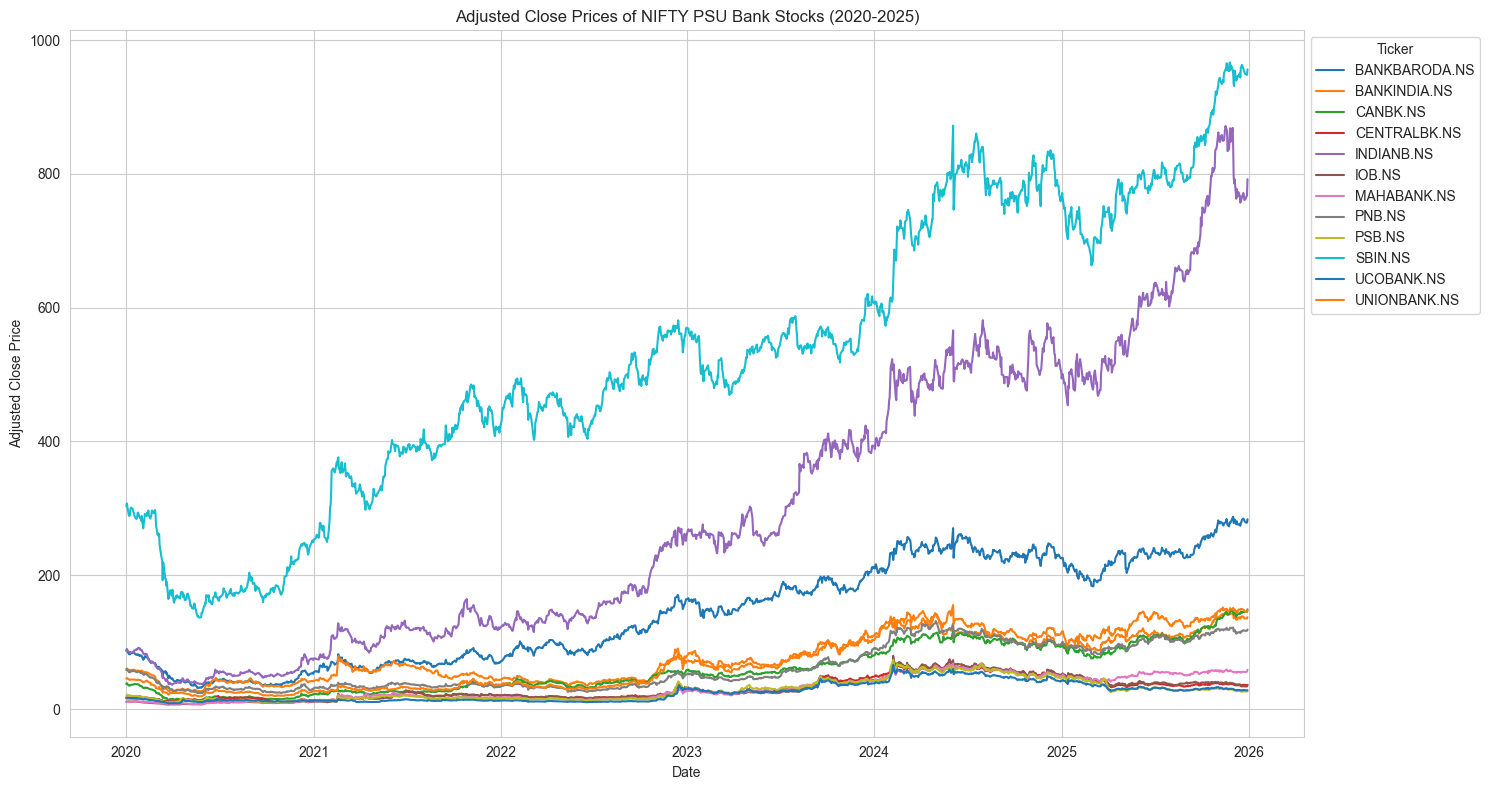

In [ ]:
plt.figure(figsize=(15, 8))
for column in clean_prices.columns:
    plt.plot(clean_prices.index, clean_prices[column], label=column)

plt.title('Adjusted Close Prices of NIFTY PSU Bank Stocks (2020-2025)')
plt.xlabel('Date')
plt.ylabel('Adjusted Close Price')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), title='Ticker')
plt.grid(True)
plt.tight_layout()
plt.show()

### Interpretation

The price movement visualization clearly illustrates the historical trends of all NIFTY PSU Bank stocks over the period. Key observations from the plot include:

-   **Diversified Trends:** While some stocks show similar directional movements, there's considerable divergence in the magnitude of price changes, particularly for stocks like `SBIN.NS` which stands out with significantly higher absolute prices compared to others.
-   **Growth Trajectories:** Most PSU bank stocks appear to have experienced substantial growth, especially from late 2022 into 2024, recovering from earlier periods of stagnation or decline.
-   **Relative Performance:** `SBIN.NS` (State Bank of India) clearly dominates the chart in terms of absolute price level and sustained upward momentum. `BANKBARODA.NS` and `CANBK.NS` also show notable growth.
-   **Periods of Volatility:** The plot helps identify periods of higher volatility or significant market events (e.g., sharp drops in early 2020 due to the COVID-19 pandemic), followed by recovery and growth phases.
-   **Long-term vs. Short-term:** The long-term upward trend for many stocks suggests overall sector recovery and investor confidence over the observed period.

This visual overview complements the summary statistics of returns by providing a graphical context to the magnitude and timing of price changes, laying the groundwork for deeper analysis into risk and correlation.

### 6.3 Daily Return Distribution

Understanding the distribution of daily returns is crucial for risk management. Financial returns often exhibit characteristics like fat tails (more extreme events than a normal distribution would suggest) and skewness. We will visualize the distributions using histograms and Kernel Density Estimation (KDE) plots to assess their shape, symmetry, and peakedness for each stock.

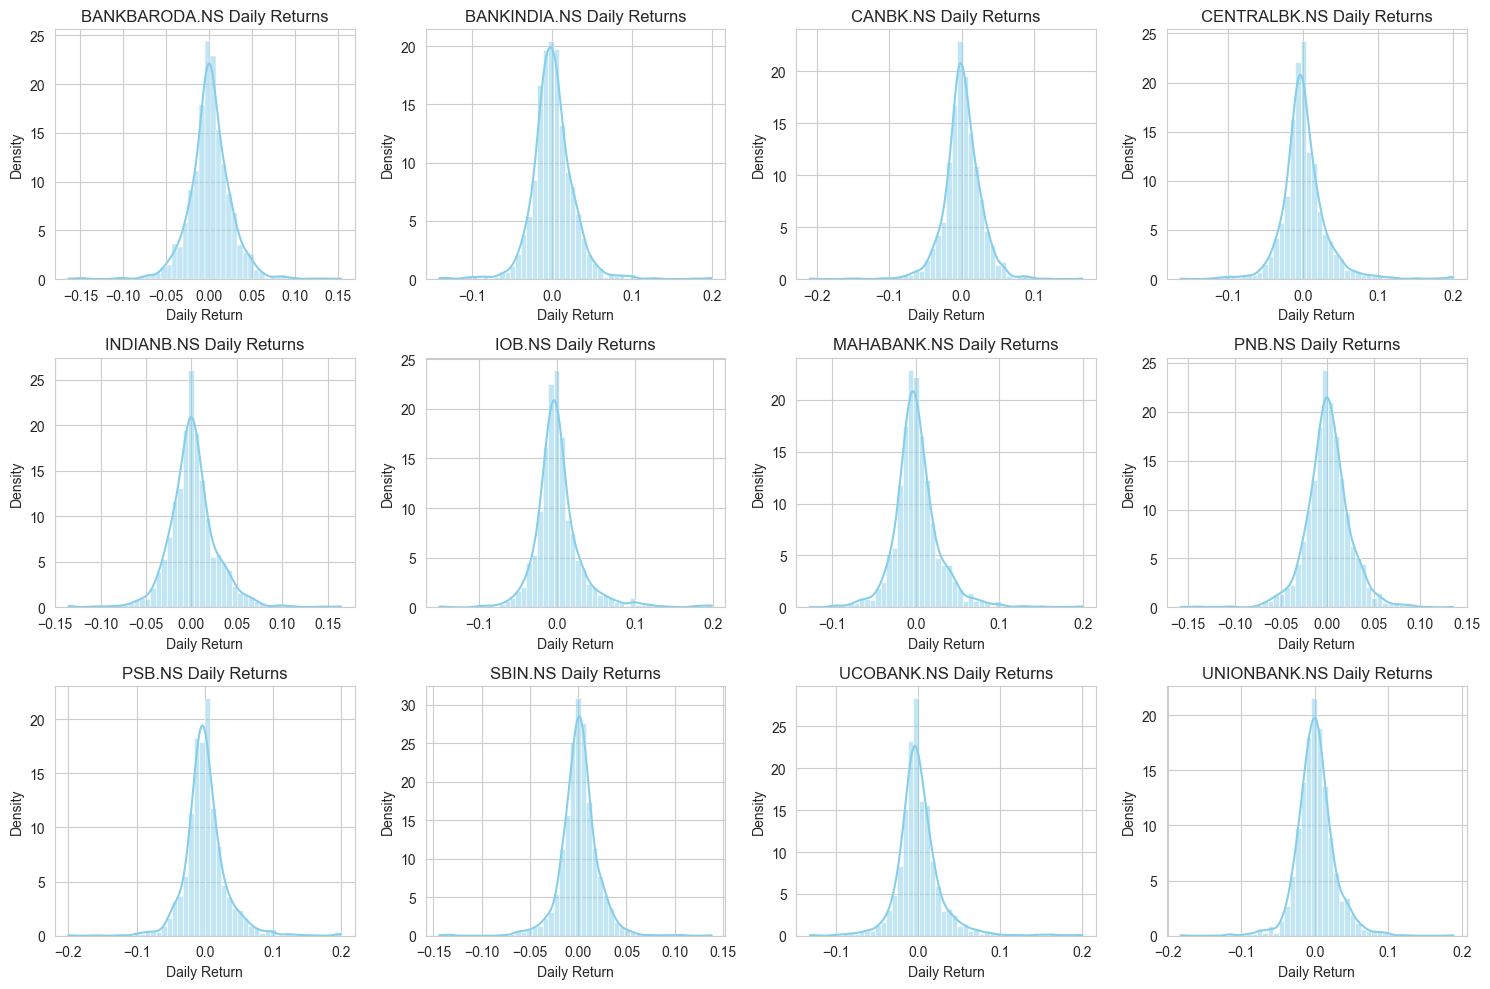

In [ ]:
plt.figure(figsize=(15, 10))
for i, column in enumerate(returns.columns):
    plt.subplot(3, 4, i + 1) # 3 rows, 4 columns for 12 plots
    sns.histplot(returns[column], bins=50, kde=True, stat='density', color='skyblue')
    plt.title(f'{column} Daily Returns')
    plt.xlabel('Daily Return')
    plt.ylabel('Density')
    plt.tight_layout()
plt.tight_layout()
plt.show()

### Interpretation

The daily return distribution plots, combining histograms and Kernel Density Estimates (KDE), offer a visual confirmation of characteristics often observed in financial returns:

-   **Leptokurtosis (Fat Tails):** Most distributions appear to be leptokurtic, meaning they have a sharper peak around the mean and fatter tails compared to a normal distribution. This indicates that extreme positive and negative returns occur more frequently than a normal distribution would predict, which is a critical consideration for risk management (e.g., VaR and ES).
-   **Slight Skewness:** While generally centered around zero, some distributions show slight asymmetry. For instance, some stocks might have a longer tail on the positive side, indicating more frequent small gains and fewer, but larger, losses, or vice-versa.
-   **Concentration Around Zero:** A large number of daily returns cluster around zero for all stocks, implying that most daily price movements are relatively small.
-   **Varying Spreads:** The spread of the distributions (visually related to standard deviation) differs across stocks. Stocks like `SBIN.NS` appear to have a tighter distribution, while others like `IOB.NS` or `PSB.NS` have a wider spread, reflecting their higher historical volatility, consistent with our `describe()` output.

These visual insights reinforce the need for risk models that can account for non-normal return distributions, particularly the presence of fat tails, to avoid underestimating potential extreme losses.

### 6.4 Volatility Comparison

Volatility, typically measured by the standard deviation of returns, is a key indicator of risk. A visual comparison of volatility across stocks helps to quickly identify the riskier assets within our portfolio. We will use a bar plot to display the annualized standard deviation of daily returns for each stock, making it easy to rank them by their historical risk levels.

C:\Users\4641s\AppData\Local\Temp\ipykernel_25484\215542323.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=annualized_volatility_sorted.index, y=annualized_volatility_sorted.values, palette='viridis')


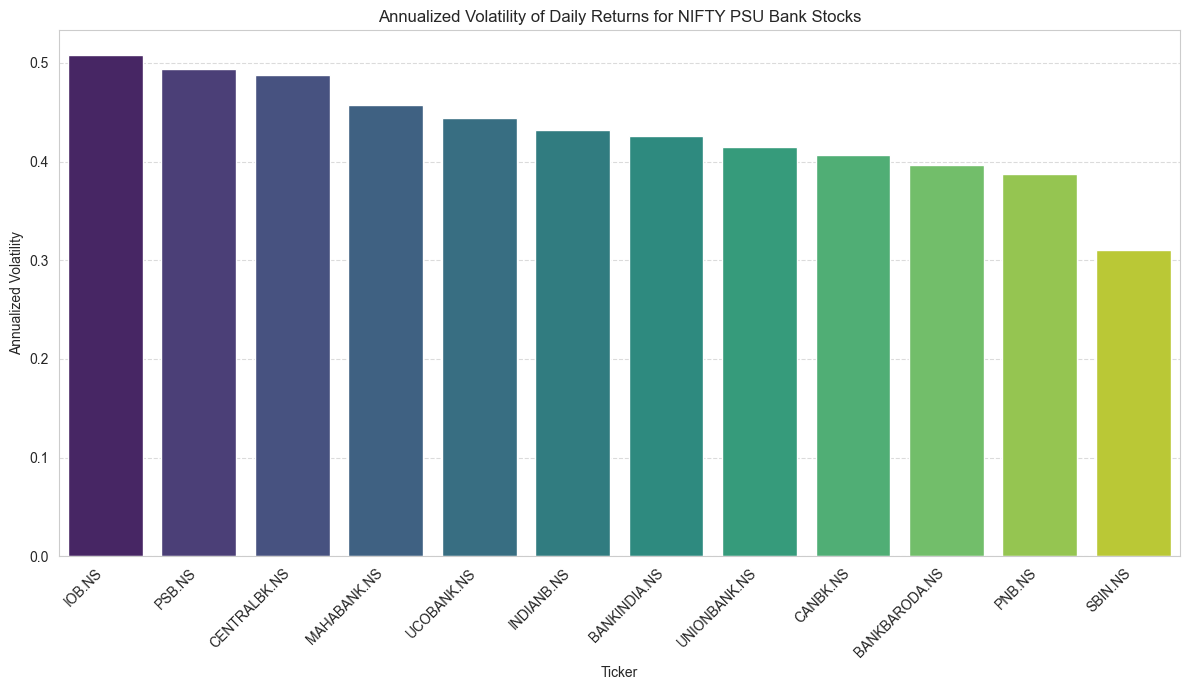

In [ ]:
# Calculate annualized volatility (standard deviation of daily returns * sqrt(252 trading days))
annualized_volatility = returns.std() * np.sqrt(252)

# Sort for better visualization
annualized_volatility_sorted = annualized_volatility.sort_values(ascending=False)

plt.figure(figsize=(12, 7))
sns.barplot(x=annualized_volatility_sorted.index, y=annualized_volatility_sorted.values, palette='viridis')
plt.title('Annualized Volatility of Daily Returns for NIFTY PSU Bank Stocks')
plt.xlabel('Ticker')
plt.ylabel('Annualized Volatility')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 6.5 Correlation Matrix

Understanding the correlation between stock returns is vital for portfolio diversification and risk management. A correlation matrix visualizes how the returns of different stocks move in relation to each other. Positive correlation indicates that stocks tend to move in the same direction, while negative correlation suggests they move in opposite directions. We will compute the pairwise correlation coefficients for all stocks in our `returns` DataFrame and visualize this using a heatmap.

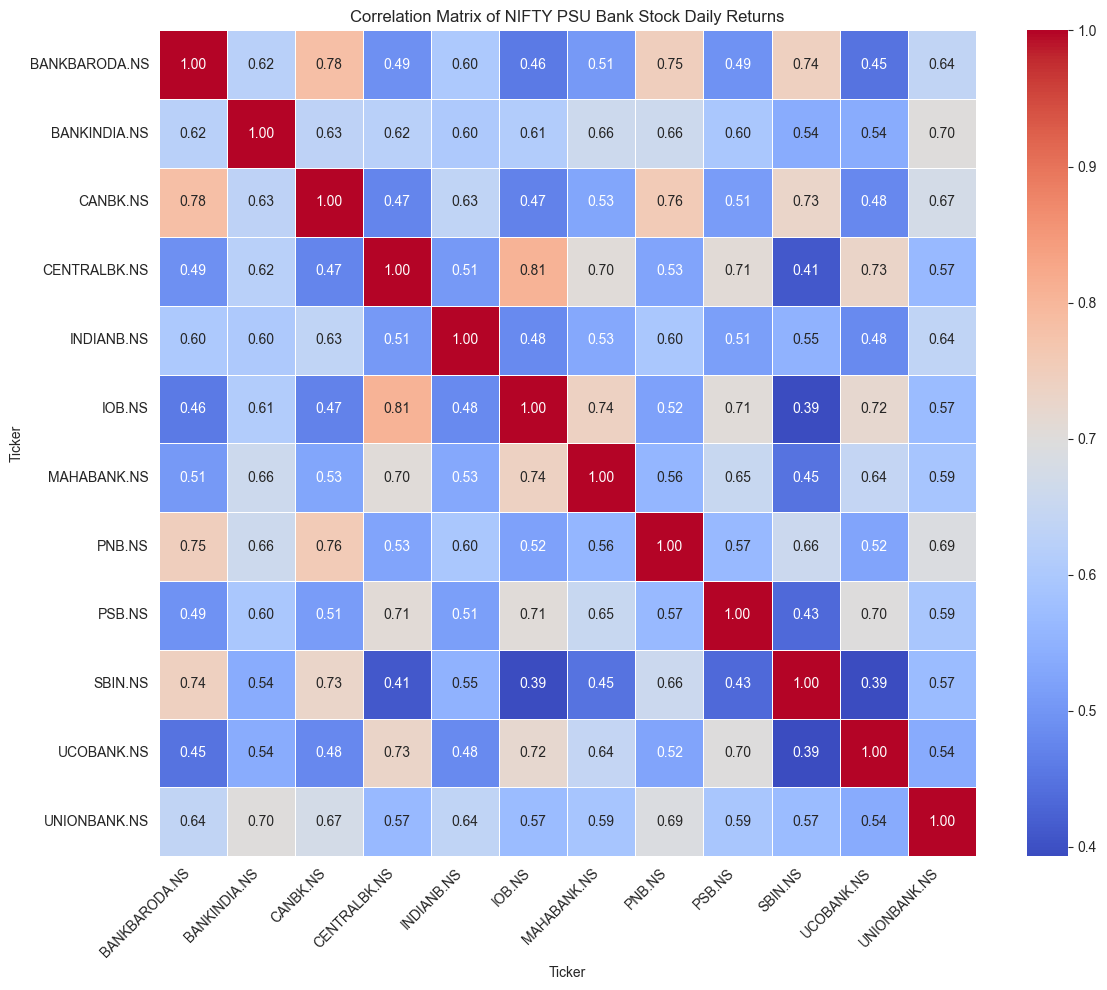

In [ ]:
# Calculate the correlation matrix
correlation_matrix = returns.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of NIFTY PSU Bank Stock Daily Returns')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation

The correlation matrix heatmap provides crucial insights into the co-movement of NIFTY PSU Bank stock returns:

-   **Generally High Positive Correlation:** As expected for stocks within the same sector (PSU banks) and market (Indian), most stocks exhibit a high positive correlation with each other, typically ranging from 0.40 to 0.80. This suggests that these stocks tend to move in the same direction, meaning they are influenced by similar macroeconomic factors, industry trends, and market sentiment.

-   **Limited Diversification Potential within Sector:** The high positive correlations indicate that simply combining these stocks within a portfolio might offer limited diversification benefits in terms of reducing systematic risk. A downturn affecting the banking sector or the broader Indian market would likely impact most, if not all, of these stocks simultaneously.

-   **Strongest Correlations:** `BANKINDIA.NS`, `CANBK.NS`, `PNB.NS`, and `UNIONBANK.NS` often show particularly strong correlations (e.g., `BANKINDIA.NS` and `CANBK.NS` with 0.70, `PNB.NS` and `UNIONBANK.NS` with 0.71), implying a very close relationship in their price movements.

-   **Relatively Weaker Correlations:** While still positive, some pairs show slightly lower correlations (e.g., `SBIN.NS` with `MAHABANK.NS` at 0.40, `SBIN.NS` with `PSB.NS` at 0.45). These lower correlations, though not negative, might offer slightly more diversification potential within the PSU bank sector compared to the higher correlated pairs.

This analysis confirms that while these stocks are part of the same sector, understanding their precise correlation values is essential for building a risk-managed portfolio, especially when considering the next steps of portfolio optimization.

#Actual Code from here

# Risk Management Analysis

## 4.1 value at Risk

In [ ]:
# SBIN.NS and UNIONBANK.NS
# We have to find Value at Risk.
# 3 methods Direct,fit t,  parametric VaR

# Select only the two required stocks
stocks = ["SBIN.NS", "UNIONBANK.NS"]
returns_var = returns.loc[:,stocks].copy()
confidence = [0.95, 0.99]

var_direct = -returns_var.quantile([1 - c for c in confidence])
var_direct.index = [f"{int(c*100)}%" for c in confidence]

var_fitted_t = {}

for stock in stocks:
    r = returns_var[stock].dropna()
    df, loc, scale = stats.t.fit(r)
    var_fitted_t[stock] = [-stats.t.ppf(1 - c, df, loc=loc, scale=scale)for c in confidence]

var_fitted_t = pd.DataFrame(var_fitted_t,index=[f"{int(c*100)}%" for c in confidence])

var_parametric_t = {}
df = 5  # Assumed degrees of freedom
for stock in stocks:
    r = returns_var[stock].dropna()
    mu = r.mean()
    sigma = r.std(ddof=1)
    var_parametric_t[stock] = [-(mu + sigma * stats.t.ppf(1 - c, df))for c in confidence]

var_parametric_t = pd.DataFrame(var_parametric_t,index=[f"{int(c*100)}%" for c in confidence])

print("Direct / Historical VaR")
display(var_direct)

print("Fitted Student's t VaR")
display(var_fitted_t)

print("Parametric Student's t VaR")
display(var_parametric_t)

Direct / Historical VaR


Ticker,SBIN.NS,UNIONBANK.NS
95%,0.028929,0.034533
99%,0.054077,0.071698


Fitted Student's t VaR


,SBIN.NS,UNIONBANK.NS
95%,0.027674,0.039471
99%,0.053783,0.072103


Parametric Student's t VaR


,SBIN.NS,UNIONBANK.NS
95%,0.038452,0.051560
99%,0.064859,0.086856


## 4.2 Expected Shortfall

In [ ]:
# calculate 95% and 99% shortfall
ES_historical = pd.DataFrame(index=[f"{int(c*100)}%" for c in confidence])

for stock in stocks:
    ES_historical[stock] = [-returns_var[stock].pipe(lambda x: x[x <= x.quantile(1-c)].mean()) for c in confidence]

display(ES_historical)

ES_t = {}



for stock in stocks:
    r = returns_var[stock].dropna()
    df, loc, scale = stats.t.fit(r)
    ES_t[stock] = [-(loc - scale * stats.t.pdf(stats.t.ppf(1-c, df),df) / (1-c) * (df + stats.t.ppf(1-c, df)**2) / (df-1)) for c in confidence]

ES_t = pd.DataFrame(ES_t,index=[f"{int(c*100)}%" for c in confidence])
display(ES_t)

,SBIN.NS,UNIONBANK.NS
95%,0.046042,0.055882
99%,0.077805,0.094562


,SBIN.NS,UNIONBANK.NS
95%,0.045726,0.061499
99%,0.082524,0.104532


In [ ]:
summary = pd.concat([
    pd.concat([var_direct.T, ES_historical.T], axis=1).assign(Method="Historical"),
    pd.concat([var_fitted_t.T, ES_t.T], axis=1).assign(Method="t-Distribution")
]).reset_index(names="Stock")

display(summary.round(5))

,Stock,95%,99%,95%,99%,Method
0,SBIN.NS,0.02893,0.05408,0.04604,0.07781,Historical
1,UNIONBANK.NS,0.03453,0.07170,0.05588,0.09456,Historical
2,SBIN.NS,0.02767,0.05378,0.04573,0.08252,t-Distribution
3,UNIONBANK.NS,0.03947,0.07210,0.06150,0.10453,t-Distribution


# Subperiod Risk Analysis

## Period 1 2020-2022

In [ ]:
# SBIN.NS and UNIONBANK.NS
# We have to find Value at Risk.
# 3 methods Direct,fit t,  parametric VaR
stocks = ["SBIN.NS", "UNIONBANK.NS"]
returns_var = returns.loc['2020-01-01':'2022-12-31',stocks].copy()
confidence = [0.95, 0.99]

var_direct = -returns_var.quantile([1 - c for c in confidence])
var_direct.index = [f"{int(c*100)}%" for c in confidence]

var_fitted_t = {}

for stock in stocks:
    r = returns_var[stock].dropna()
    df, loc, scale = stats.t.fit(r)
    var_fitted_t[stock] = [-stats.t.ppf(1 - c, df, loc=loc, scale=scale)for c in confidence]

var_fitted_t = pd.DataFrame(var_fitted_t,index=[f"{int(c*100)}%" for c in confidence])

var_parametric_t = {}
df = 5  # Assumed degrees of freedom
for stock in stocks:
    r = returns_var[stock].dropna()
    mu = r.mean()
    sigma = r.std(ddof=1)
    var_parametric_t[stock] = [-(mu + sigma * stats.t.ppf(1 - c, df))for c in confidence]

var_parametric_t = pd.DataFrame(var_parametric_t,index=[f"{int(c*100)}%" for c in confidence])

# print("Direct / Historical VaR")
# display(var_direct)

# print("Fitted Student's t VaR")
# display(var_fitted_t)

# print("Parametric Student's t VaR")
# display(var_parametric_t)

# calculate 95% and 99% shortfall
ES_historical = pd.DataFrame(index=[f"{int(c*100)}%" for c in confidence])

for stock in stocks:
    ES_historical[stock] = [-returns_var[stock].pipe(lambda x: x[x <= x.quantile(1-c)].mean()) for c in confidence]
# print('Direct ES')
# display(ES_historical)

ES_t = {}

for stock in stocks:
    r = returns_var[stock].dropna()
    df, loc, scale = stats.t.fit(r)
    ES_t[stock] = [-(loc - scale * stats.t.pdf(stats.t.ppf(1-c, df),df) / (1-c) * (df + stats.t.ppf(1-c, df)**2) / (df-1)) for c in confidence]

ES_t = pd.DataFrame(ES_t,index=[f"{int(c*100)}%" for c in confidence])
# print('Fitted t distribution ES')
# display(ES_t)

summary = pd.concat([
    pd.concat([var_direct.T, ES_historical.T], axis=1).assign(Method="Historical"),
    pd.concat([var_fitted_t.T, ES_t.T], axis=1).assign(Method="t-Distribution")
]).reset_index(names="Stock")

display(summary.round(5))

,Stock,95%,99%,95%,99%,Method
0,SBIN.NS,0.03650,0.06208,0.05472,0.08359,Historical
1,UNIONBANK.NS,0.03916,0.07919,0.06286,0.09828,Historical
2,SBIN.NS,0.03400,0.06217,0.05286,0.08912,t-Distribution
3,UNIONBANK.NS,0.04460,0.08578,0.07326,0.13229,t-Distribution


## Period 2 2023-2025

In [ ]:
# SBIN.NS and UNIONBANK.NS
# We have to find Value at Risk.
# 3 methods Direct,fit t,  parametric VaR
stocks = ["SBIN.NS", "UNIONBANK.NS"]
returns_var = returns.loc['2023-01-01':'2025-12-31',stocks].copy()
confidence = [0.95, 0.99]

var_direct = -returns_var.quantile([1 - c for c in confidence])
var_direct.index = [f"{int(c*100)}%" for c in confidence]

var_fitted_t = {}

for stock in stocks:
    r = returns_var[stock].dropna()
    df, loc, scale = stats.t.fit(r)
    var_fitted_t[stock] = [-stats.t.ppf(1 - c, df, loc=loc, scale=scale)for c in confidence]

var_fitted_t = pd.DataFrame(var_fitted_t,index=[f"{int(c*100)}%" for c in confidence])

var_parametric_t = {}
df = 5  # Assumed degrees of freedom
for stock in stocks:
    r = returns_var[stock].dropna()
    mu = r.mean()
    sigma = r.std(ddof=1)
    var_parametric_t[stock] = [-(mu + sigma * stats.t.ppf(1 - c, df))for c in confidence]

var_parametric_t = pd.DataFrame(var_parametric_t,index=[f"{int(c*100)}%" for c in confidence])

# print("Direct / Historical VaR")
# display(var_direct)

# print("Fitted Student's t VaR")
# display(var_fitted_t)

# print("Parametric Student's t VaR")
# display(var_parametric_t)

# calculate 95% and 99% shortfall
ES_historical = pd.DataFrame(index=[f"{int(c*100)}%" for c in confidence])

for stock in stocks:
    ES_historical[stock] = [-returns_var[stock].pipe(lambda x: x[x <= x.quantile(1-c)].mean()) for c in confidence]
# print('Direct ES')
# display(ES_historical)

ES_t = {}

for stock in stocks:
    r = returns_var[stock].dropna()
    df, loc, scale = stats.t.fit(r)
    ES_t[stock] = [-(loc - scale * stats.t.pdf(stats.t.ppf(1-c, df),df) / (1-c) * (df + stats.t.ppf(1-c, df)**2) / (df-1)) for c in confidence]

ES_t = pd.DataFrame(ES_t,index=[f"{int(c*100)}%" for c in confidence])
# print('Fitted t distribution ES')
# display(ES_t)

summary = pd.concat([
    pd.concat([var_direct.T, ES_historical.T], axis=1).assign(Method="Historical"),
    pd.concat([var_fitted_t.T, ES_t.T], axis=1).assign(Method="t-Distribution")
]).reset_index(names="Stock")

display(summary.round(5))

,Stock,95%,99%,95%,99%,Method
0,SBIN.NS,0.02001,0.03542,0.03183,0.05562,Historical
1,UNIONBANK.NS,0.03039,0.05851,0.04720,0.07933,Historical
2,SBIN.NS,0.02072,0.03810,0.03241,0.05512,t-Distribution
3,UNIONBANK.NS,0.03426,0.05749,0.04930,0.07603,t-Distribution


## Discussion

# March 2020 Stress Test

## Adding March 2020 data to the 2023-2025 year.

In [ ]:
# SBIN.NS and UNIONBANK.NS
# We have to find Value at Risk.
# 3 methods Direct,fit t,  parametric VaR
stocks = ["SBIN.NS", "UNIONBANK.NS"]
returns_var = pd.concat([returns.loc['2020-03-01':'2020-03-31',stocks].copy(),returns.loc['2023-01-01':'2025-12-31',stocks].copy()])
confidence = [0.95, 0.99]

var_direct = -returns_var.quantile([1 - c for c in confidence])
var_direct.index = [f"{int(c*100)}%" for c in confidence]

var_fitted_t = {}

for stock in stocks:
    r = returns_var[stock].dropna()
    df, loc, scale = stats.t.fit(r)
    var_fitted_t[stock] = [-stats.t.ppf(1 - c, df, loc=loc, scale=scale)for c in confidence]

var_fitted_t = pd.DataFrame(var_fitted_t,index=[f"{int(c*100)}%" for c in confidence])

var_parametric_t = {}
df = 5  # Assumed degrees of freedom
for stock in stocks:
    r = returns_var[stock].dropna()
    mu = r.mean()
    sigma = r.std(ddof=1)
    var_parametric_t[stock] = [-(mu + sigma * stats.t.ppf(1 - c, df))for c in confidence]

var_parametric_t = pd.DataFrame(var_parametric_t,index=[f"{int(c*100)}%" for c in confidence])

# print("Direct / Historical VaR")
# display(var_direct)

# print("Fitted Student's t VaR")
# display(var_fitted_t)

# print("Parametric Student's t VaR")
# display(var_parametric_t)

# calculate 95% and 99% shortfall
ES_historical = pd.DataFrame(index=[f"{int(c*100)}%" for c in confidence])

for stock in stocks:
    ES_historical[stock] = [-returns_var[stock].pipe(lambda x: x[x <= x.quantile(1-c)].mean()) for c in confidence]
# print('Direct ES')
# display(ES_historical)

ES_t = {}

for stock in stocks:
    r = returns_var[stock].dropna()
    df, loc, scale = stats.t.fit(r)
    ES_t[stock] = [-(loc - scale * stats.t.pdf(stats.t.ppf(1-c, df),df) / (1-c) * (df + stats.t.ppf(1-c, df)**2) / (df-1)) for c in confidence]

ES_t = pd.DataFrame(ES_t,index=[f"{int(c*100)}%" for c in confidence])
# print('Fitted t distribution ES')
# display(ES_t)

summary = pd.concat([
    pd.concat([var_direct.T, ES_historical.T], axis=1).assign(Method="Historical"),
    pd.concat([var_fitted_t.T, ES_t.T], axis=1).assign(Method="t-Distribution")
]).reset_index(names="Stock")

display(summary.round(5))

,Stock,95%,99%,95%,99%,Method
0,SBIN.NS,0.02184,0.05094,0.04421,0.08986,Historical
1,UNIONBANK.NS,0.03170,0.06313,0.05384,0.09642,Historical
2,SBIN.NS,0.02287,0.04723,0.04033,0.07789,t-Distribution
3,UNIONBANK.NS,0.04031,0.07918,0.06789,0.12642,t-Distribution


## Discussion

# Volatility Estimation and Forecasting

## 7.1 EWMA Volatility

In [ ]:
stocks = ["SBIN.NS", "UNIONBANK.NS"]

ewma_volatility = pd.DataFrame(index=returns.index)
lambda_estimates = {}

for stock in stocks:
    r = (returns[stock].dropna() * 100)
    model = ZeroMean(r, volatility=EWMAVariance(lam=None), distribution=StudentsT())
    result = model.fit(disp="off")
    lambda_estimates[stock] = result.params["lam"]
    ewma_volatility.loc[r.index, stock] = result.conditional_volatility

print("MLE estimates of lambda:")
display(pd.Series(lambda_estimates, name="Lambda"))


MLE estimates of lambda:


C:\Users\4641s\AppData\Local\Programs\Python\Python313\Lib\site-packages\arch\univariate\distribution.py:553: RuntimeWarning: divide by zero encountered in log
  lls -= 0.5 * (log(sigma2))
C:\Users\4641s\AppData\Local\Programs\Python\Python313\Lib\site-packages\arch\univariate\distribution.py:554: RuntimeWarning: divide by zero encountered in divide
  lls -= ((nu + 1) / 2) * (log(1 + (resids**2.0) / (sigma2 * (nu - 2))))
C:\Users\4641s\AppData\Local\Programs\Python\Python313\Lib\site-packages\arch\univariate\distribution.py:554: RuntimeWarning: invalid value encountered in subtract
  lls -= ((nu + 1) / 2) * (log(1 + (resids**2.0) / (sigma2 * (nu - 2))))


SBIN.NS         0.977709
UNIONBANK.NS    0.927622
Name: Lambda, dtype: float64

## 7.2 EWMA Forecasting Regression

In [ ]:
stocks = ["SBIN.NS", "UNIONBANK.NS"]
regression_results = {}

for stock in stocks:
    data = pd.DataFrame({
        "squared_return_next_day": returns[stock].shift(-1) ** 2,
        "ewma_variance": (ewma_volatility[stock] / 100) ** 2
    }).replace([np.inf, -np.inf], np.nan).dropna()

    X = sm.add_constant(data["ewma_variance"])
    y = data["squared_return_next_day"]

    model = sm.OLS(y, X).fit()
    regression_results[stock] = model

    print(f"\n===== {stock} =====")
    print(f"Alpha (Intercept):       {model.params['const']:.6f}")
    print(f"Eta (EWMA Variance):     {model.params['ewma_variance']:.6f}")
    print(f"Alpha p-value:           {model.pvalues['const']:.6g}")
    print(f"Eta p-value:              {model.pvalues['ewma_variance']:.6g}")
    print(f"Alpha significant (5%):   {'Yes' if model.pvalues['const'] < 0.05 else 'No'}")
    print(f"Eta significant (5%):    {'Yes' if model.pvalues['ewma_variance'] < 0.05 else 'No'}")
    print(f"R-squared:               {model.rsquared:.6f}")
    print(f"Adjusted R-squared:      {model.rsquared_adj:.6f}")

    data["predicted_squared_return"] = model.predict(X)
    print(f"RMSE:                    {np.sqrt(mean_squared_error(y, data['predicted_squared_return'])):.8f}")


===== SBIN.NS =====
Alpha (Intercept):       0.000072
Eta (EWMA Variance):     0.777472
Alpha p-value:           0.137796
Eta p-value:              1.70565e-16
Alpha significant (5%):   No
Eta significant (5%):    Yes
R-squared:               0.044808
Adjusted R-squared:      0.044164
RMSE:                    0.00120237

===== UNIONBANK.NS =====
Alpha (Intercept):       0.000384
Eta (EWMA Variance):     0.437286
Alpha p-value:           7.09106e-07
Eta p-value:              7.79283e-07
Alpha significant (5%):   Yes
Eta significant (5%):    Yes
R-squared:               0.016340
Adjusted R-squared:      0.015677
RMSE:                    0.00183663


# EWMA v/s Rolling Window Volatility

In [ ]:
stocks = ["SBIN.NS", "UNIONBANK.NS"]

comparison_results = []
rolling_volatility = pd.DataFrame(index=returns.index)

for stock in stocks:
    lam = lambda_estimates[stock]
    window = int(np.ceil(np.log(0.10) / np.log(lam)))
    r = returns[stock].replace([np.inf, -np.inf], np.nan)
    rolling_volatility[stock] = r.rolling(window).std(ddof=0)
    rolling_variance = rolling_volatility[stock] ** 2
    ewma_variance = (ewma_volatility[stock] / 100) ** 2

    comparison = pd.DataFrame({
        "realized_variance": r.shift(-1) ** 2,
        "EWMA_variance": ewma_variance,
        "Rolling_variance": rolling_variance
    }).replace([np.inf, -np.inf], np.nan).dropna()

    eps = 1e-12
    comparison["EWMA_variance"] = comparison["EWMA_variance"].clip(lower=eps)
    comparison["Rolling_variance"] = comparison["Rolling_variance"].clip(lower=eps)

    realized = comparison["realized_variance"]

    for method in ["EWMA", "Rolling"]:
        forecast = comparison[f"{method}_variance"]

        mse = np.mean((realized - forecast) ** 2)
        rmse = np.sqrt(mse)

        comparison_results.append({
            "Stock": stock,
            "Method": method,
            "Window": window if method == "Rolling" else np.nan,
            "Observations": len(comparison),
            "MSE": mse,
            "RMSE": rmse
        })

results_df = pd.DataFrame(comparison_results)

print("Estimated EWMA decay factors and rolling-window lengths:")
for stock in stocks:
    print(
        f"{stock}: lambda = {lambda_estimates[stock]:.6f}, "
        f"window = {int(np.ceil(np.log(0.10) / np.log(lambda_estimates[stock])))} days"
    )

print("\nVolatility Forecast Comparison:")
print(results_df.round(8).to_string(index=False))

Estimated EWMA decay factors and rolling-window lengths:
SBIN.NS: lambda = 0.977709, window = 103 days
UNIONBANK.NS: lambda = 0.927622, window = 31 days

Volatility Forecast Comparison:
       Stock  Method  Window  Observations          MSE     RMSE
     SBIN.NS    EWMA     NaN          1382 7.800000e-07 0.000886
     SBIN.NS Rolling   103.0          1382 8.000000e-07 0.000896
UNIONBANK.NS    EWMA     NaN          1454 3.530000e-06 0.001879
UNIONBANK.NS Rolling    31.0          1454 3.540000e-06 0.001882


# Portfolio Optimization

# Minimum Variance Portfolio

After preparing the data we move towards Optimization.
* Under a long-only constraint (no shorting, weights between 0% and 100%), the optimizer (ef.min_volatility()) searches for the exact asset allocation that produces the absolute lowest portfolio risk (volatility), regardless of return.

* Outcome: The resulting portfolio achieves an annual expected return of 24.9% with 29.3% annualized volatility (Sharpe Ratio: 0.85).

Why the weights look like this
Dominance of SBIN.NS (~68%):

* State Bank of India is the largest, most stable PSU bank. Because it has significantly lower standalone price volatility compared to smaller peers, the optimizer uses it as the portfolio's primary stabilizing anchor.

Secondary weights (UCOBANK.NS at ~16.5%, others <5%):
* These stocks are included because their return patterns offer marginal diversification benefits (lower correlation) against SBI.

Zero allocations (0.0):
* Mean-variance optimization naturally creates "corner solutions." Redundant stocks that have higher volatility and high positive correlation with SBI are discarded completely to keep total portfolio risk as low as possible.

In [ ]:
stock_returns = returns.dropna()

mu = expected_returns.mean_historical_return(
    stock_returns,
    returns_data=True,
    compounding=False,
    frequency=252
)

S = risk_models.sample_cov(
    stock_returns,
    returns_data=True,
    frequency=252
)

ef = EfficientFrontier(mu, S, weight_bounds=(0, 1))
ef.min_volatility()

weights = ef.clean_weights()
ef.portfolio_performance(verbose=True)

print("\nPortfolio Weights:")
print(weights)

Expected annual return: 24.9%
Annual volatility: 29.3%
Sharpe Ratio: 0.85

Portfolio Weights:
OrderedDict({'BANKBARODA.NS': 0.0, 'BANKINDIA.NS': 0.03277, 'CANBK.NS': 0.0, 'CENTRALBK.NS': 0.0, 'INDIANB.NS': 0.04368, 'IOB.NS': 0.0, 'MAHABANK.NS': 0.03436, 'PNB.NS': 0.0195, 'PSB.NS': 0.0, 'SBIN.NS': 0.67955, 'UCOBANK.NS': 0.16544, 'UNIONBANK.NS': 0.0247})


# Mean Variance Efficinet Frontier

#Process
* From the basket of 12 indian PSU bank stocks we start by filtering out the missing daily return values to prevent calculation errors.

* mu estimates annualized historical returns using daily arithmetic returns across a standard 252-day trading year.

* S computes the annualized sample covariance matrix, capturing both each stock's standalone volatility and the pairwise co-movements across all 12 banks

#Explanations
* EfficientFrontier(..., weight_bounds=(0, 1)) sets a long-only rule (no short-selling, allocations between 0% and 100%).

* ef.min_volatility() solves for the exact weight distribution that minimizes portfolio variance

* Marginal positions in secondary banks (~2% to 4.4%):INDIANB.NS (4.4%), MAHABANK.NS (3.4%), BANKINDIA.NS (3.3%), UNIONBANK.NS (2.5%), and PNB.NS (2.0%) receive minor slivers where slight non-linear covariance offsets offer tiny risk reductions.

* Zero allocations (0.0% for 5 stocks):BANKBARODA, CANBK, CENTRALBK, IOB, and PSB are excluded. In quadratic optimization with a non-negativity constraint, assets that offer redundant risk-return profiles or strong positive correlations with cheaper risk alternatives result in "corner solutions" and are assigned zero weight.

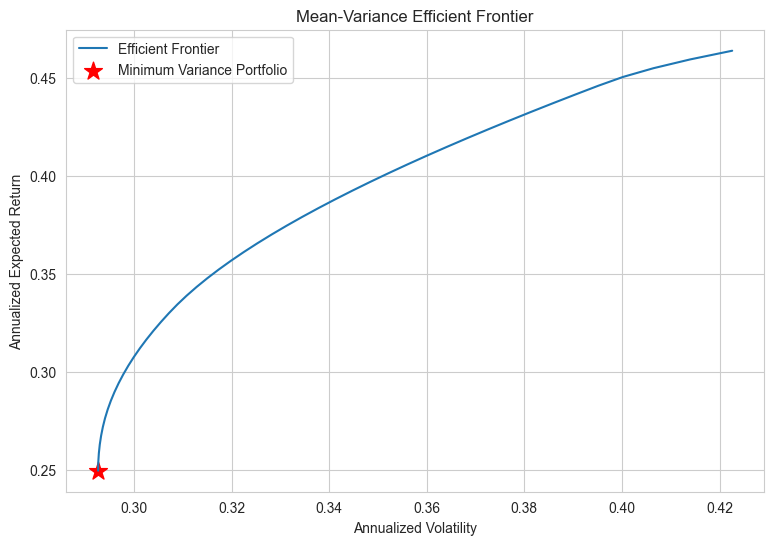

Minimum Variance Portfolio
BANKBARODA.NS    0.00000
BANKINDIA.NS     0.03277
CANBK.NS         0.00000
CENTRALBK.NS     0.00000
INDIANB.NS       0.04368
IOB.NS           0.00000
MAHABANK.NS      0.03436
PNB.NS           0.01950
PSB.NS           0.00000
SBIN.NS          0.67955
UCOBANK.NS       0.16544
UNIONBANK.NS     0.02470
dtype: float64
Expected Return: 24.9377%
Volatility:      29.2640%
Variance:        0.085638

Frontier Portfolio 1
Expected Return: 24.9377%
Volatility:      29.2640%
BANKBARODA.NS    0.00000
BANKINDIA.NS     0.03277
CANBK.NS         0.00000
CENTRALBK.NS     0.00000
INDIANB.NS       0.04368
IOB.NS           0.00000
MAHABANK.NS      0.03436
PNB.NS           0.01950
PSB.NS           0.00000
SBIN.NS          0.67955
UCOBANK.NS       0.16544
UNIONBANK.NS     0.02470
dtype: float64

Frontier Portfolio 25
Expected Return: 35.6549%
Volatility:      31.9877%
BANKBARODA.NS    0.00000
BANKINDIA.NS     0.00000
CANBK.NS         0.00000
CENTRALBK.NS     0.00000
INDIANB.NS      

In [ ]:
stock_returns = returns.dropna()

mu = expected_returns.mean_historical_return(
    stock_returns, returns_data=True, compounding=False, frequency=252
)

S = risk_models.sample_cov(
    stock_returns, returns_data=True, frequency=252
)

ef_min = EfficientFrontier(mu, S, weight_bounds=(0, 1))
ef_min.min_volatility()
min_weights = ef_min.clean_weights()
min_return, min_volatility, _ = ef_min.portfolio_performance()

target_returns = np.linspace(min_return, mu.max(), 50)
frontier_returns = []
frontier_volatility = []
frontier_weights = []

for target in target_returns:
    try:
        ef = EfficientFrontier(mu, S, weight_bounds=(0, 1))
        ef.efficient_return(target_return=target)
        ret, vol, _ = ef.portfolio_performance()

        frontier_returns.append(ret)
        frontier_volatility.append(vol)
        frontier_weights.append(ef.clean_weights())
    except:
        continue

plt.figure(figsize=(9, 6))
plt.plot(frontier_volatility, frontier_returns, label="Efficient Frontier")
plt.scatter(min_volatility, min_return, color="red", marker="*", s=180,
            label="Minimum Variance Portfolio")
plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Expected Return")
plt.title("Mean-Variance Efficient Frontier")
plt.grid(True)
plt.legend()
plt.show()

# Minimum variance portfolio
print("Minimum Variance Portfolio")
print(pd.Series(min_weights))
print(f"Expected Return: {min_return:.4%}")
print(f"Volatility:      {min_volatility:.4%}")
print(f"Variance:        {min_volatility**2:.6f}")

# Selected portfolios along the frontier
selected = [0, len(frontier_returns) // 2, len(frontier_returns) - 1]

for i in selected:
    print(f"\nFrontier Portfolio {i + 1}")
    print(f"Expected Return: {frontier_returns[i]:.4%}")
    print(f"Volatility:      {frontier_volatility[i]:.4%}")
    print(pd.Series(frontier_weights[i]))

# Variance-Covariance Matrix Estimation

It calculates sample covariance and EWMA covariance to capture both traditional historical co-movements and recent volatility trends in your stock data. It then applies the Ledoit-Wolf shrinkage method, which blends noisy sample data with a structured target matrix to significantly reduce estimation errors. Finally, it generates an Oracle Approximating shrinkage matrix to ensure complete numerical stability for your portfolio optimization routines

In [ ]:
stock_returns = returns.dropna()

# 1. Sample covariance matrix
S_sample = risk_models.sample_cov(
    stock_returns, returns_data=True, frequency=252
)

# 2. EWMA covariance matrix
S_ewma = risk_models.exp_cov(
    stock_returns, returns_data=True, span=180, frequency=252
)

# 3. Shrinkage covariance matrix (Ledoit-Wolf)
S_shrinkage = risk_models.CovarianceShrinkage(
    stock_returns, returns_data=True, frequency=252
).ledoit_wolf()

# 4. Sparse inverse covariance matrix
S_sparse = risk_models.CovarianceShrinkage(
    stock_returns, returns_data=True, frequency=252
).oracle_approximating()

##Step-by-Step Code Breakdown

*   Expected Returns & Matrix Dictionary (mu, covariance_matrices):
    Calculates annualized historical returns (mu) and groups all four pre-calculated covariance matrices into a dictionary for batch processing.

*   Optimization Loop:
    Loops through each covariance matrix to compute the Minimum Variance Portfolio with no short-selling constraints (weight_bounds=(0, 1)), storing the optimal weights, return, volatility, and variance.

*   Performance & Weight Comparison Tables:
    Combines the results into Pandas DataFrames and prints side-by-side numerical comparisons of portfolio metrics and individual stock allocations.

*   Weight Comparison Bar Chart:
    Generates a grouped bar chart (weights_comparison.plot) showing how asset allocations shift across different covariance estimation techniques.

*   Efficient Frontier Plotting:
    Loops through each covariance method again to generate and plot multiple Efficient Frontier curves on a single graph, marking each respective Minimum Variance Portfolio with a star (*) for visual comparison.

Minimum Variance Portfolio Comparison
           Expected Return  Volatility  Variance
Method                                          
Sample            0.249377    0.292640  0.085638
EWMA              0.252531    0.162235  0.026320
Shrinkage         0.250086    0.292627  0.085631
Sparse            0.249588    0.292574  0.085599

Portfolio Weights Comparison
               Sample    EWMA  Shrinkage  Sparse
BANKBARODA.NS  0.0000  0.0000     0.0000  0.0000
BANKINDIA.NS   0.0328  0.0000     0.0343  0.0332
CANBK.NS       0.0000  0.0000     0.0000  0.0000
CENTRALBK.NS   0.0000  0.0000     0.0000  0.0000
INDIANB.NS     0.0437  0.0333     0.0470  0.0447
IOB.NS         0.0000  0.0299     0.0000  0.0000
MAHABANK.NS    0.0344  0.0000     0.0359  0.0348
PNB.NS         0.0195  0.0000     0.0281  0.0221
PSB.NS         0.0000  0.0000     0.0000  0.0000
SBIN.NS        0.6796  0.9210     0.6630  0.6746
UCOBANK.NS     0.1654  0.0158     0.1643  0.1651
UNIONBANK.NS   0.0247  0.0000     0.0274  0.0255


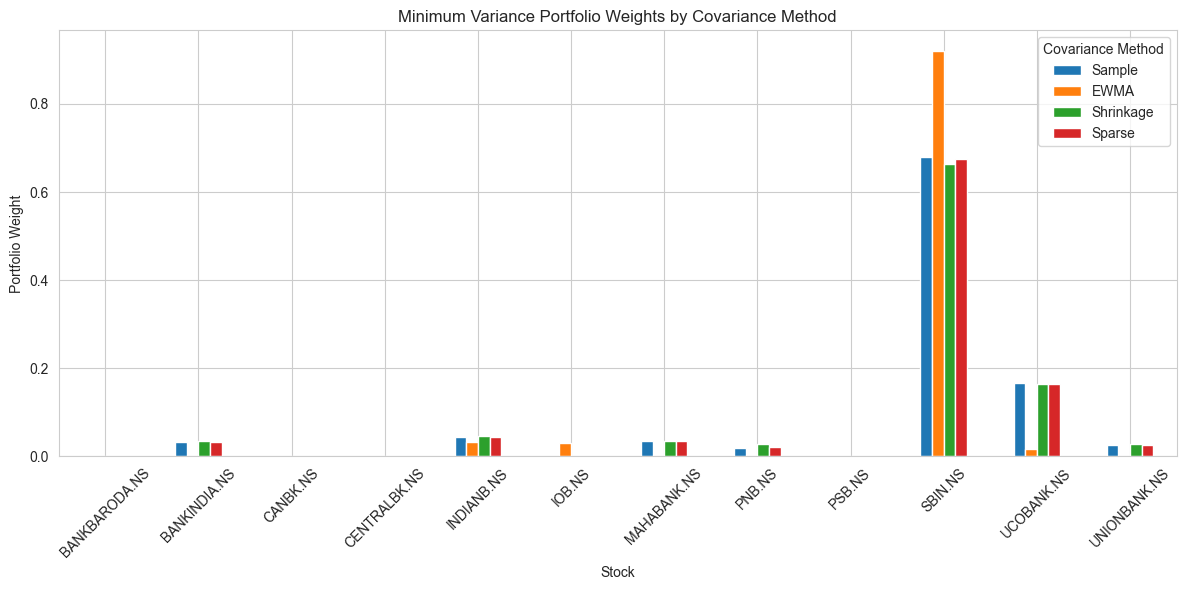

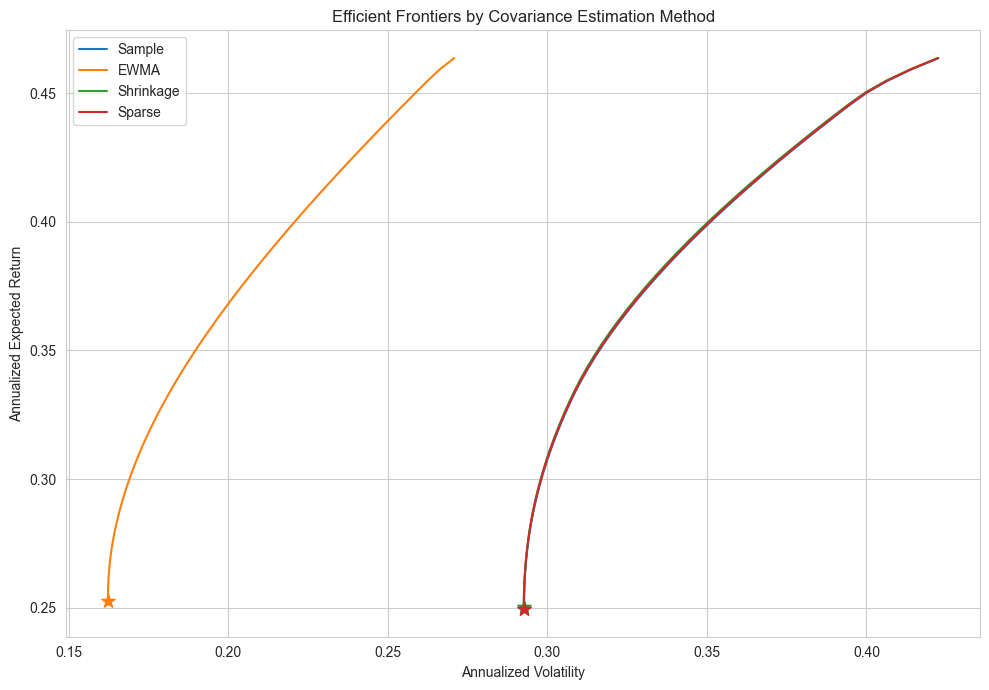

In [ ]:
mu = expected_returns.mean_historical_return(
    stock_returns,
    returns_data=True,
    compounding=False,
    frequency=252
)

covariance_matrices = {
    "Sample": S_sample,
    "EWMA": S_ewma,
    "Shrinkage": S_shrinkage,
    "Sparse": S_sparse
}

# Store minimum variance portfolio results
portfolio_results = []
portfolio_weights = {}

for name, S in covariance_matrices.items():
    ef = EfficientFrontier(mu, S, weight_bounds=(0, 1))
    ef.min_volatility()

    weights = ef.clean_weights()
    portfolio_weights[name] = weights

    ret, vol, _ = ef.portfolio_performance()

    portfolio_results.append({
        "Method": name,
        "Expected Return": ret,
        "Volatility": vol,
        "Variance": vol ** 2
    })

# Compare minimum variance portfolios
comparison = pd.DataFrame(portfolio_results).set_index("Method")

print("Minimum Variance Portfolio Comparison")
print(comparison.round(6))

# Compare portfolio weights
weights_comparison = pd.DataFrame(portfolio_weights)
print("\nPortfolio Weights Comparison")
print(weights_comparison.round(4))

# Plot weight comparison
weights_comparison.plot(kind="bar", figsize=(12, 6))
plt.title("Minimum Variance Portfolio Weights by Covariance Method")
plt.ylabel("Portfolio Weight")
plt.xlabel("Stock")
plt.xticks(rotation=45)
plt.legend(title="Covariance Method")
plt.tight_layout()
plt.show()

# Construct and plot efficient frontiers
plt.figure(figsize=(10, 7))

for name, S in covariance_matrices.items():
    frontier_returns = []
    frontier_volatility = []

    min_ef = EfficientFrontier(mu, S, weight_bounds=(0, 1))
    min_ef.min_volatility()
    min_return, min_vol, _ = min_ef.portfolio_performance()

    target_returns = np.linspace(min_return, max(mu), 50)

    for target in target_returns:
        try:
            ef = EfficientFrontier(mu, S, weight_bounds=(0, 1))
            ef.efficient_return(target_return=target)
            ret, vol, _ = ef.portfolio_performance()

            frontier_returns.append(ret)
            frontier_volatility.append(vol)
        except:
            continue

    plt.plot(frontier_volatility, frontier_returns, label=name)
    plt.scatter(min_vol, min_return, marker="*", s=100)

plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Expected Return")
plt.title("Efficient Frontiers by Covariance Estimation Method")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

* The Feasible Risk-Return Set: Each curve represents the optimal combinations of expected return and volatility available to your PSU bank stocks under a specific covariance estimation method.
* Impact of Covariance Estimation: By plotting all four curves on the same graph, it visually demonstrates how estimation noise or smoothing (like EWMA vs. Shrinkage) shifts the efficient frontier and alters portfolio risk estimates.
* Minimum Variance Anchors: The star markers ($\star$) at the tip of each curve highlight the exact Global Minimum Variance (GMV) portfolio point for that specific covariance model, allowing you to see which method yields the lowest overall risk.

* The GMV portfolio is the specific combination of assets that achieves the absolute lowest possible risk (volatility) across your entire universe of stocks, completely independent of their expected returns.

# Portfolio Optimization With Short Selling

###Short-Selling Enabled

 Computes minimum variance portfolios and efficient frontiers allowing short sales (weight_bounds=(-np.inf, np.inf)).

Minimum Variance Portfolio Comparison
           Expected Return  Volatility  Variance
Method                                          
Sample            0.240650    0.289463  0.083789
EWMA              0.273149    0.158585  0.025149
Shrinkage         0.242486    0.289980  0.084089
Sparse            0.241208    0.289563  0.083847

Portfolio Weights Comparison
               Sample    EWMA  Shrinkage  Sparse
BANKBARODA.NS -0.0678  0.0262    -0.0561 -0.0642
BANKINDIA.NS   0.0555 -0.0705     0.0551  0.0554
CANBK.NS      -0.1490  0.0312    -0.1358 -0.1450
CENTRALBK.NS  -0.0054 -0.0237    -0.0042 -0.0050
INDIANB.NS     0.0692  0.0896     0.0702  0.0695
IOB.NS        -0.0277  0.0525    -0.0266 -0.0274
MAHABANK.NS    0.0551 -0.0345     0.0556  0.0552
PNB.NS         0.0969 -0.1310     0.0961  0.0967
PSB.NS        -0.0338 -0.1093    -0.0320 -0.0332
SBIN.NS        0.7610  0.9876     0.7339  0.7528
UCOBANK.NS     0.1921  0.1660     0.1896  0.1914
UNIONBANK.NS   0.0538  0.0159     0.0542  0.0539


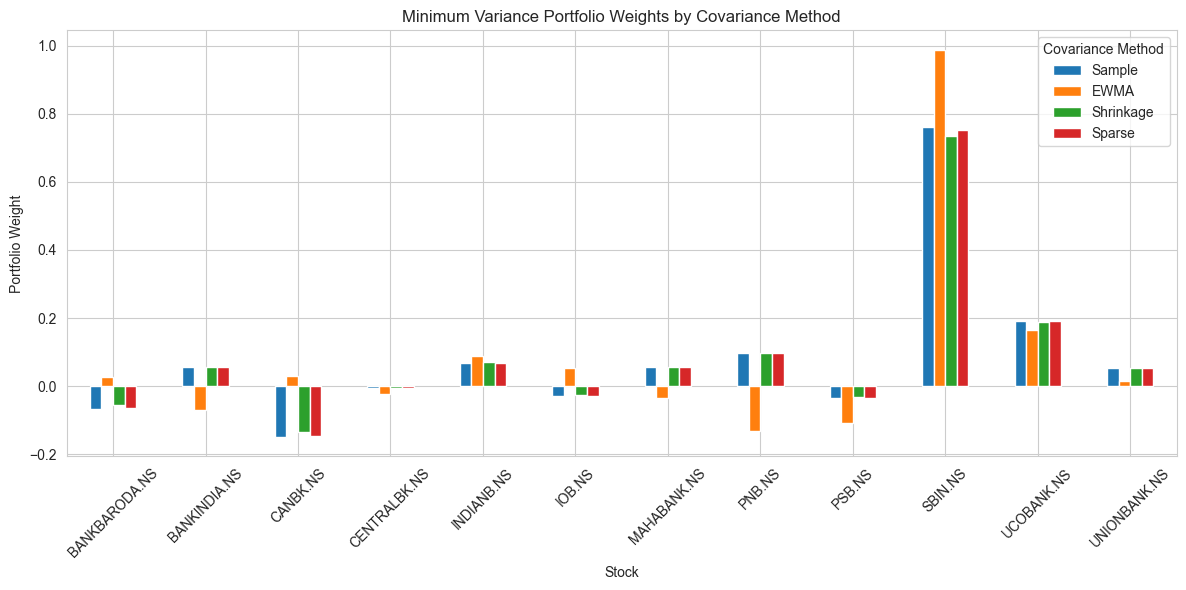

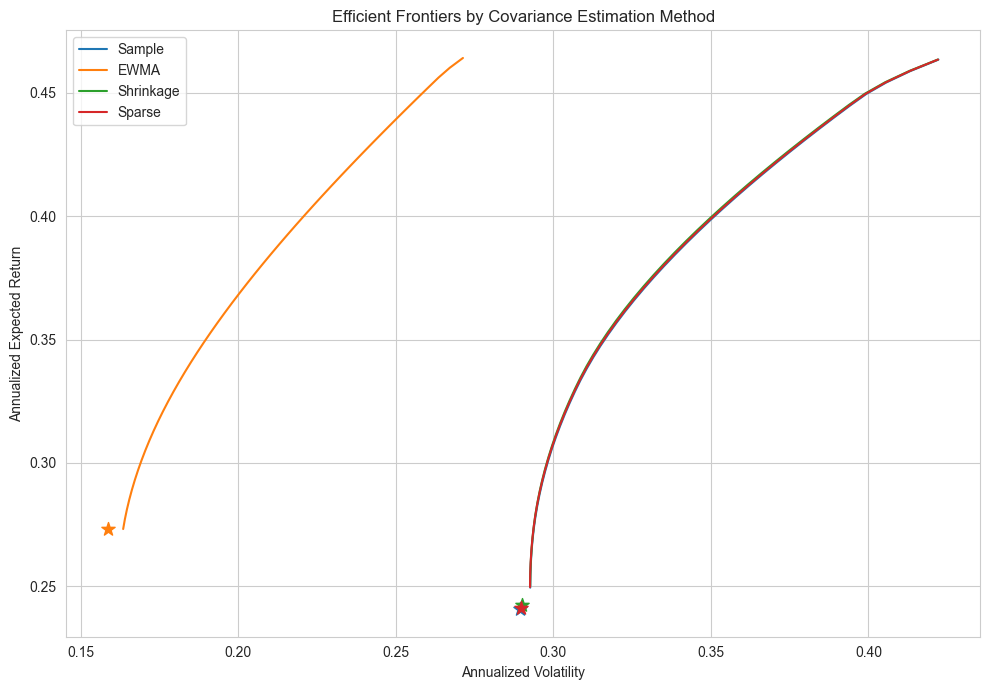

In [ ]:
mu = expected_returns.mean_historical_return(
    stock_returns,
    returns_data=True,
    compounding=False,
    frequency=252
)

covariance_matrices = {
    "Sample": S_sample,
    "EWMA": S_ewma,
    "Shrinkage": S_shrinkage,
    "Sparse": S_sparse
}

# Store minimum variance portfolio results
portfolio_results = []
portfolio_weights = {}

for name, S in covariance_matrices.items():
    ef = EfficientFrontier(mu, S,weight_bounds=(-np.inf,np.inf))
    ef.min_volatility()

    weights = ef.clean_weights()
    portfolio_weights[name] = weights

    ret, vol, _ = ef.portfolio_performance()

    portfolio_results.append({
        "Method": name,
        "Expected Return": ret,
        "Volatility": vol,
        "Variance": vol ** 2
    })

# Compare minimum variance portfolios
comparison = pd.DataFrame(portfolio_results).set_index("Method")

print("Minimum Variance Portfolio Comparison")
print(comparison.round(6))

# Compare portfolio weights
weights_comparison = pd.DataFrame(portfolio_weights)
print("\nPortfolio Weights Comparison")
print(weights_comparison.round(4))

# Plot weight comparison
weights_comparison.plot(kind="bar", figsize=(12, 6))
plt.title("Minimum Variance Portfolio Weights by Covariance Method")
plt.ylabel("Portfolio Weight")
plt.xlabel("Stock")
plt.xticks(rotation=45)
plt.legend(title="Covariance Method")
plt.tight_layout()
plt.show()

# Construct and plot efficient frontiers
plt.figure(figsize=(10, 7))

for name, S in covariance_matrices.items():
    frontier_returns = []
    frontier_volatility = []

    min_ef = EfficientFrontier(mu, S, weight_bounds=(-np.inf, np.inf))
    min_ef.min_volatility()
    min_return, min_vol, _ = min_ef.portfolio_performance()

    target_returns = np.linspace(min_return, max(mu), 50)

    for target in target_returns:
        try:
            ef = EfficientFrontier(mu, S, weight_bounds=(0, 1))
            ef.efficient_return(target_return=target)
            ret, vol, _ = ef.portfolio_performance()

            frontier_returns.append(ret)
            frontier_volatility.append(vol)
        except:
            continue

    plt.plot(frontier_volatility, frontier_returns, label=name)
    plt.scatter(min_vol, min_return, marker="*", s=100)

plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Expected Return")
plt.title("Efficient Frontiers by Covariance Estimation Method")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Comparisons: Portfolio Optimization With vs. Without Short Selling

When we compare the **Minimum Variance Portfolios** under the **long-only constraint** (no short-selling) and the **short-selling-enabled** framework across the different covariance methods (Sample, EWMA, Shrinkage, Sparse), several key mathematical and practical dynamics emerge.

### 1. Key Quantitative Observations from Our Results
* **Risk Reduction:** Allowing short sales consistently decreases the portfolio's annualized volatility. For example, under the **Sample Covariance** model, volatility drops from **29.26%** (long-only) to **28.95%** (short-selling enabled). For **EWMA**, it drops from **16.22%** to **15.86%**.
* **Asset Concentration:** Long-only constraints result in "corner solutions" where 5 out of 12 stocks are completely ignored (assigned 0% weight). When short selling is allowed, the optimizer goes short on correlated or volatile assets (e.g., shorting `CANBK.NS` at **-14.90%** and `BANKBARODA.NS` at **-6.78%** under Sample Covariance) to aggressively fund an even larger long exposure in State Bank of India (`SBIN.NS`), which expands from **67.96%** to **76.10%**.

---

### 2. What This Means for an Individual (Human Retail Investor)

#### **The Good (Pros):**
* **Long-Only Security:** For a typical human investor, the **No Short Selling** portfolio is highly accessible, intuitive, and safe from catastrophic losses. The worst-case loss on any long-only asset is capped at 100% of the invested capital.
* **Lower Transaction Costs & Simplicity:** Managing a long-only portfolio is simple, has low turnover, requires no margin account setup, and incurs no borrowing fees or margin calls.

#### **The Bad (Cons):**
* **Suboptimal Hedging:** An individual investor cannot protect their portfolio during sector-wide downturns. Because they cannot short, they are forced to hold high-volatility assets or accept a higher baseline portfolio risk (**29.26%** vs. **28.95%**).
* **Forced Exclusion:** Due to corner solutions, they are forced to completely ignore several banks that could potentially offer micro-diversification benefits if minor shorting were permitted.

---

### 3. What This Means for a Hedge Fund

#### **The Good (Pros):**
* **Capital Efficiency & Absolute Return:** By enabling short selling, a hedge fund can extract absolute returns (alpha) regardless of market direction. They can exploit pairwise statistical anomalies (e.g., shorting `CANBK.NS` and going long `SBIN.NS` to capture the spread difference while neutralizing sector risk).
* **Lower Overall Systemic Risk:** They can drive the portfolio's volatility down to its absolute mathematical minimum (**15.86%** in EWMA), protecting their institutional clients from broad market drawdowns.

#### **The Bad (Cons):**
* **Unlimited Risk & Margin Calls:** Short selling carries theoretically unlimited risk because a stock's price can rise infinitely. A sudden, unexpected short squeeze in a highly shorted stock like `CANBK.NS` can cause catastrophic, compounding losses.
* **High Operational Costs:** Hedge funds must pay share-borrowing fees, manage daily margin requirements, and face execution risk (inability to borrow shares of illiquid PSU banks). These friction costs can quickly wipe out the minor **0.31%** risk reduction gained by moving from long-only to short-selling frameworks.

# Loading Factor Investing

In [ ]:
import pandas as pd
import statsmodels.api as sm

# 1. Load factor data
factors = pd.read_csv(
    "2025-12_FourFactors_and_Market_Returns_Daily_SurvivorshipBiasAdjusted.csv"
)

# Convert factor dates to datetime
factors["Date"] = pd.to_datetime(factors["Date"], errors="coerce")
factors = factors.dropna(subset=["Date"])
factors = factors.set_index("Date").sort_index()

# Rename factor columns
factors = factors.rename(columns={
    "MF": "MKT",
    "WML": "MOM"
})

# 2. Convert stock-return dates to datetime
returns.index = pd.to_datetime(returns.index, errors="coerce")
returns = returns.loc[~returns.index.isna()].sort_index()

# Four Factor Betas

In [ ]:
data = returns.join(
    factors[["MKT", "SMB", "HML", "MOM", "RF"]],
    how="inner"
).dropna()

factor_betas = {}

for stock in returns.columns:
    y = data[stock] - data["RF"]
    X = sm.add_constant(data[["MKT", "SMB", "HML", "MOM"]])
    model = sm.OLS(y, X, missing="drop").fit()
    factor_betas[stock] = {
        "Market Beta": model.params["MKT"],
        "Size Beta": model.params["SMB"],
        "Value Beta": model.params["HML"],
        "Momentum Beta": model.params["MOM"],
        "Alpha": model.params["const"],
        "R-squared": model.rsquared
    }

factor_betas_df = pd.DataFrame(factor_betas).T

print("\nFour-Factor Betas for All Stocks")
print(factor_betas_df[
    ["Market Beta", "Size Beta", "Value Beta", "Momentum Beta"]
].round(4))

# print("\nRegression Summary Statistics")
# print(factor_betas_df[["Alpha", "R-squared"]].round(4))


Four-Factor Betas for All Stocks
               Market Beta  Size Beta  Value Beta  Momentum Beta
BANKBARODA.NS       0.0120     0.0037      0.0071        -0.0011
BANKINDIA.NS        0.0110     0.0079      0.0077        -0.0016
CANBK.NS            0.0142     0.0052      0.0065        -0.0012
CENTRALBK.NS        0.0095     0.0104      0.0094         0.0005
INDIANB.NS          0.0112     0.0073      0.0073        -0.0021
IOB.NS              0.0103     0.0105      0.0093         0.0009
MAHABANK.NS         0.0096     0.0104      0.0094        -0.0006
PNB.NS              0.0111     0.0054      0.0081        -0.0019
PSB.NS              0.0116     0.0091      0.0088        -0.0013
SBIN.NS             0.0114     0.0006      0.0045        -0.0022
UCOBANK.NS          0.0088     0.0099      0.0069        -0.0006
UNIONBANK.NS        0.0115     0.0076      0.0068        -0.0003


# CAPM Beta Analysis

In [ ]:
capm_data = returns.join(
    factors[["MKT"]],
    how="inner"
).dropna()

def calculate_capm_betas(data, start_date, end_date):
    period = data.loc[start_date:end_date]
    betas = {}

    for stock in returns.columns:
        temp = period[[stock, "MKT"]].dropna()

        X = sm.add_constant(temp["MKT"])
        y = temp[stock]

        model = sm.OLS(y, X).fit()
        betas[stock] = model.params["MKT"]

    return pd.Series(betas)

beta_2020_2022 = calculate_capm_betas(
    capm_data, "2020-01-01", "2022-12-31"
)

beta_2023_2025 = calculate_capm_betas(
    capm_data, "2023-01-01", "2025-12-31"
)

capm_comparison = pd.DataFrame({
    "β (2020–2022)": beta_2020_2022,
    "β (2023–2025)": beta_2023_2025
})

capm_comparison["Change"] = (
    capm_comparison["β (2023–2025)"]
    - capm_comparison["β (2020–2022)"]
)

print(capm_comparison.round(4))

               β (2020–2022)  β (2023–2025)  Change
BANKBARODA.NS         0.0127         0.0133  0.0006
BANKINDIA.NS          0.0110         0.0138  0.0028
CANBK.NS              0.0149         0.0147 -0.0002
CENTRALBK.NS          0.0079         0.0176  0.0097
INDIANB.NS            0.0124         0.0109 -0.0016
IOB.NS                0.0091         0.0176  0.0085
MAHABANK.NS           0.0090         0.0153  0.0063
PNB.NS                0.0109         0.0148  0.0039
PSB.NS                0.0097         0.0193  0.0096
SBIN.NS               0.0122         0.0101 -0.0020
UCOBANK.NS            0.0065         0.0160  0.0095
UNIONBANK.NS          0.0115         0.0142  0.0026
